# ConsumidorIA — Entrega II: Orquestração com LangGraph e Sistema Multiagente Coordenado (A2A + MCP)

#### **Disciplina:** Engenharia de Agentes e IA Agentica  
#### **Professor:** Paulo Augusto de Souza Moreira

#### **Aluno:** Bryan Wille Souto Braga
#### **E-mail academico:** [1599029@pucminas.edu.br](mailto:1599029@pucminas.edu.br)
#### **Data de entrega:** Novembro/2026

---

## Objetivo do Trabalho

A ideia aqui nessa Entrega II foi pegar o agente unico q fiz na Entrega I (**ConsumidorIA** — triagem e analise de reclamações de SAC/Procon) e evoluir a arquitetura pra um **Sistema Multiagente Coordenado**, dividindo em 2 etapas principais:

1. **Etapa 1 — Reorganização com LangGraph:**
   - Troquei aquele loop procedural com `while` manual da primeira entrega por um grafo de estados explicito (`StateGraph`), separando bem o q e no deterministico (`perceive`, `validate`, `action`), o q e chamada de modelo (`model`, `finalize`), execução de tools (`tools`) e desvios condicionais com `add_conditional_edges`.
2. **Etapa 2 — Sistema Multiagente Coordenado (LangGraph + Protocolo A2A + MCP):**
   - Em vez de deixar tudo nas costas de um agente so, dividi as responsabilidades em 4 papeis isolados pra evitar bagunça de contexto e respeitar permissoes:
     - **`SupervisorAgent` (Coordenador com LangGraph + A2A Client):** faz o discovery automatico dos especialistas via *Agent Cards*, monta o plano em ondas, dispara agentes independentes em paralelo com `asyncio.gather` e aplica a validação deterministica final.
     - **`KnowledgeAgent` (Especialista Normativo — Servidor A2A `/knowledge`):** cuida exclusivamente do **Vector RAG** (`BaseConhecimentoRAG`) com o CDC, politicas e manuais. Não mexe com dados de consumidor nem MCP pra não vazar dado.
     - **`OperationsAgent` (Especialista Operacional — Servidor A2A `/operations`):** cuida exclusivamente das consultas via **MCP Client** (`ClienteMCPConsumidorIA`) pra buscar dados de pedido, consumidor (com CPF mascarado), empresa e interações de SAC. Não interpreta regras do RAG.
     - **`StrategyAgent` (Especialista de Parecer — Servidor A2A `/strategy`):** não acessa nem RAG nem MCP. Recebe so os *Artifacts* estruturados ja mastigados pelo Knowledge e pelo Operations e monta a recomendação final no contrato do `FINAL_SCHEMA`.

Vale lembrar q o sistema ajuda na triagem e fundamenta a analise, mas **não toma decisão judicial**, não aplica multa e manda obrigatoriamente pra humano qualquer caso de alto risco ou acima de R$ 5.000,00.

## 1. Caracterização do Caso

O cenario e de uma instituição de mediação de conflitos de consumo tipo SAC ou Procon, recebendo broncas de clientes por varios canais (WhatsApp, e-mail, telefone, formulario). Os problemas variam entre produto com defeito, atraso na entrega, cobrança indevida ou produto diferente do comprado.

Pra analisar qualquer reclamação (`reclamacao_id`, tipo `REC001`), a gente precisa cruzar 2 mundos bem diferentes:
- **Conhecimento Normativo e Documental (Estatico):** CDC (Codigo de Defesa do Consumidor), regras de atendimento, prazos e procedimentos de escalonamento (`base_conhecimento_chunks.csv` via Vector RAG).
- **Dados Operacionais do Caso (Dinamicos):** cadastro basico do cliente (CPF mascarado), status do pedido e garantia, SLA da empresa e historico de mensagens trocadas no SAC (`consumidores.csv`, `pedidos_contratos.csv`, `empresas.csv`, `produtos_servicos.csv`, `interacoes_sac.csv` via MCP Server).

## 2. O Problema do Agente Unico da Entrega I

Na Entrega I tava rodando tudo num `while` procedural grandao, e isso gerava alguns gargalos chatos:
1. Misturava logica de controle de fluxo, retries e limites junto com as chamadas do LLM;
2. Jogava no mesmo prompt os textos de leis/manuais junto com logs brutos de SAC e dados pessoais;
3. Um unico agente tinha acesso a todas as ferramentas ao mesmo tempo, sem isolamento de segurança nem de contexto.

## 3. Fundamentação da Arquitetura

### 3.1. Reorganização Inicial com LangGraph

A primeira melhoria foi tirar o `while` solto e colocar um `StateGraph` do LangGraph pra estruturar o fluxo. O modelo continua o mesmo, mas a engenharia em volta fica bem mais confiavel:

- **Estado Compartilhado e Tipado (`TypedDict`):** todas as informações ficam num schema tipado (`SingleAgentGraphState` / `MultiAgentState`), em vez de variaveis soltas.
- **Roteamento Explicito (`Conditional Edges`):** pra saber se continua chamando tools (`"tools"`) ou se vai pro parecer (`"finalize"`), a gente usa `add_conditional_edges`, sem precisar de `if/break` perdido no meio do codigo.
- **Ciclos Controlados:** o retorno `tools -> model` deixa evidente no desenho do grafo o ciclo de raciocinio e ação (ReAct).

```text
┌──────────────────────────────────────────────────────────────────────────────────┐
│              ETAPA 1 — REORGANIZAÇAO DO AGENTE COM LANGGRAPH                     │
└──────────────────────────────────────────────────────────────────────────────────┘

  [START] ──► [perceive] ──► [model] ──(se precisa de tools)──► [tools (MCP/RAG)]
              (deterministico)  ▲  │                                     │
                                │  └────(sem mais tools)────────┐        │
                                └────────(FunctionResponse)─────┼────────┘
                                                                ▼
                             [END] ◄── [action] ◄── [validate] ◄── [finalize]
                                    (deterministico) (deterministico) (LLM JSON)
```

---

### 3.2. Diferença Pratica: `Node ≠ Tool ≠ Agente`

Uma regra importante de design aqui: **não adianta sair criando agente pra tudo**. Cada peça tem um nivel de autonomia diferente:

| Conceito | Grau de Autonomia | Quando usar | Aplicação no ConsumidorIA |
|---|---|---|---|
| **Node / Funçao** | **Zero (Deterministico)** | Regra de negocio fixa, validação de schema, parse de regex e logs de auditoria. Não precisa de LLM pra isso. | `perceive_intake` (valida regex `r"REC\d+"` e pega a reclamação), `validate_and_finalize` (aplica trava de R$ 5k/risco e valida `FINAL_SCHEMA`), `action` (salva o CSV de auditoria). |
| **Tool / Capability (MCP)** | **Baixo (Funçao focada)** | Consulta pontual a banco ou API com parametros bem definidos, sem objetivo proprio. | As 5 funções do MCP Server (`consultar_reclamacao`, `consultar_consumidor`, `consultar_pedido`, `consultar_empresa_produto`, `consultar_interacoes`). |
| **Agente (A2A)** | **Alto (Raciocinio e contexto proprio)** | Especialista q tem objetivo, contexto proprio e devolve um *Artifact* fechado. | `SupervisorAgent`, `KnowledgeAgent`, `OperationsAgent` e `StrategyAgent`. |

**Pq não criar um agente pra cada etapa ou pra cada tool?**
- Se colocasse `perceive` ou `validate` como agente, ia gastar chamada de LLM a toa, demorar mais e correr risco de alucinação em validações basicas q uma linha de Python resolve com 100% de certeza.
- Se criasse 1 agente pra cada uma das 5 tools MCP (`consultar_consumidor`, etc.), ia virar um caos de mensagens A2A trocadas pra fazer uma simples leitura de tabela. Agrupar tudo no `OperationsAgent` e muito mais rapido e organizado.

## 4. Arquitetura Multiagente Coordenada (Etapa 2 — LangGraph + A2A + MCP)

### 4.1. Topologia Supervisor com Execução Paralela em Ondas

A estrutura final ficou assim: o Supervisor orquestra o fluxo geral via LangGraph e delega pros especialistas via protocolo A2A. Na primeira onda, o Knowledge e o Operations rodam juntos em paralelo (`asyncio.gather`), e na segunda onda o Strategy recebe os dados prontos pra consolidar:

```text
┌───────────────────────────────────────────────────────────────────────────────────────────┐
│                      CONSUMIDORIA — ARQUITETURA MULTIAGENTE FINAL                         │
│               Interno do Coordenador: LangGraph • Entre Agentes: Protocolo A2A            │
└───────────────────────────────────────────────────────────────────────────────────────────┘

                                  ┌──────────────────────┐
                                  │  Usuario / Avaliador │
                                  │  reclamacao_id=REC.. │
                                  └──────────┬───────────┘
                                             │
                                             ▼
┌───────────────────────────────────────────────────────────────────────────────────────────┐
│                     SUPERVISOR AGENT (LangGraph StateGraph + A2A Client)                  │
│  1. perceive_intake (Node deterministico: valida REC\d+ e carrega a reclamação)           │
│  2. supervisor_plan (Node planejador: ve Agent Cards e decide o proximo passo)            │
│  3. delegate_a2a    (Node executor: dispara especialistas da onda via asyncio.gather)     │
│  4. validate_and_finalize (Node deterministico: trava R$ 5k/risco + valida schema e audit)│
└──────────────┬─────────────────────────────────────────┬──────────────────────────┬───────┘
               │ A2A (JSON-RPC 1.0)                      │ A2A (JSON-RPC 1.0)       │ A2A (JSON-RPC 1.0)
               │ Onda 1 (Paralela)                       │ Onda 1 (Paralela)        │ Onda 2 (Sequencial)
               ▼                                         ▼                          ▼
┌──────────────────────────────┐     ┌──────────────────────────────────┐     ┌───────────────────────────┐
│       KNOWLEDGE AGENT        │     │         OPERATIONS AGENT         │     │      STRATEGY AGENT       │
│   A2A Server (/knowledge)    │     │     A2A Server (/operations)     │     │   A2A Server (/strategy)  │
│  "Quais normas se aplicam?"  │     │ "Quais os fatos operacionais?"   │     │ "Qual parecer recomendar?"│
│  • Não mexe em MCP nem PII   │     │ • Não mexe no RAG normativo      │     │ • Sem acesso a RAG nem MCP│
│  • Filtra chunks citados     │     │ • Junta dados e logs do SAC      │     │ • So recebe os Artifacts  │
└──────────────┬───────────────┘     └─────────────────┬────────────────┘     │   de Knowledge+Operations │
               │                                       │ MCP (stdio/JSON-RPC) │ • Cospe o FINAL_SCHEMA    │
               ▼                                       ▼                      └───────────────────────────┘
┌──────────────────────────────┐     ┌──────────────────────────────────┐
│     BaseConhecimentoRAG      │     │     MCP Server ConsumidorIA      │
│  Embeddings Gemini / TF-IDF  │     │ 5 Ferramentas Operacionais:      │
│  base_conhecimento_chunks    │     │ consumidor • pedido • interações │
│  (CDC, Politicas, Manuais)   │     │ empresa_produto • reclamacao     │
└──────────────────────────────┘     └──────────────────────────────────┘
```

---

### 4.2. Papel de Cada Agente

| Agente | Onde roda | Criterio de Separação | O que faz | O que NAO faz (Isolamento) |
|---|---|---|---|---|
| **`SupervisorAgent`** | `StateGraph` local + `A2AAgentClient` | **Coordenação e Governança** | Descobre os especialistas via *Agent Cards* (`/.well-known/agent-card.json`), planeja as ondas, junta os *Artifacts* e aplica as travas deterministicas finais. | Não acessa direto a base de embeddings do RAG nem fica parseando logs brutos de SAC. |
| **`KnowledgeAgent`** | Servidor A2A `http://127.0.0.1:8126/knowledge` | **Especialista em Regras + LGPD** | Consulta o `BaseConhecimentoRAG` sobre normas estaticas (`base_conhecimento_chunks.csv`), resume as regras aplicaveis e garante q `chunks_citados` venham so do q foi recuperado de verdade. | **Não tem cliente MCP** e não recebe dados pessoais do consumidor (CPF, nome) nem conversas de SAC. |
| **`OperationsAgent`** | Servidor A2A `http://127.0.0.1:8126/operations` | **Acesso Operacional + Paralelismo** | Unico q fala com o `ClienteMCPConsumidorIA` pra consultar consumidor, pedido, empresa e interações de SAC, devolvendo um JSON limpo (`OPERATIONS_ARTIFACT_SCHEMA`). | **Não mexe no RAG** nem inventa tese juridica sobre a disputa. |
| **`StrategyAgent`** | Servidor A2A `http://127.0.0.1:8126/strategy` | **Isolamento de Decisão** | Recebe so os resumos mastigados (`Knowledge Artifact` e `Operations Artifact`) e cruza tudo pra gerar o parecer final no formato do `FINAL_SCHEMA`. | **Sem RAG e sem MCP.** Não corre risco de sofrer injeçao de prompt por causa de texto bruto de SAC e não chama ferramentas. |

---

### 4.3. Pq Multiagente ficou melhor q Agente Unico aqui?

| Aspecto | Agente Unico (Entrega I) | Sistema Multiagente (Entrega II) | Vantagem Pratica |
|---|---|---|---|
| **Isolamento de Contexto** | Tudo caia no mesmo prompt: regras do CDC, schemas de 6 tools e logs enormes de conversa do SAC. | Cada agente roda na sua propria janela e devolve so um *Artifact* enxuto pro proximo. | O `StrategyAgent` recebe so informação mastigada e estruturada, reduzindo muito alucinação e confusao. |
| **Privacidade e LGPD** | O mesmo loop q lia leis tinha acesso a CPF e dados cadastrais. | O `KnowledgeAgent` so recebe a categoria do problema, sem nenhum dado pessoal; quem cuida de cadastro e so o `OperationsAgent`. | Segregação clara de permissoes. |
| **Tempo de Execução** | Fazia chamadas uma atras da outra sequencialmente. | **Onda 1 paralela (`asyncio.gather`):** `KnowledgeAgent` (RAG) e `OperationsAgent` (MCP) rodam juntos antes da **Onda 2** (`StrategyAgent`). | O tempo da primeira fase cai pro tempo do mais demorado: $\approx \max(t_{\text{knowledge}}, t_{\text{operations}})$. |
| **Facilidade de Manutenção** | Se quisesse mudar uma tool ou prompt de RAG, tinha q mexer no loopzao unico de todo mundo. | Especialistas desacoplados conversando via A2A; o Supervisor so enxerga os *Agent Cards*. | Da pra mexer no RAG ou adicionar consultas no MCP sem quebrar o orquestrador. |

---

### 4.4. Diferença entre os Protocolos (`A2A ≠ MCP`)

- **`A2A (Agent2Agent Protocol v1.0)`:** usado na comunicação **entre agentes**. Serve pra descoberta (`AgentCard`), envio de mensagens, acompanhamento de tarefas (`Task` passando por `SUBMITTED` -> `WORKING` -> `COMPLETED`) e entrega de pacotes de dados (`Artifact`).
- **`MCP (Model Context Protocol)`:** usado na conexão **agente ↔ ferramenta**. Serve pro `OperationsAgent` (e pro intake) descobrir (`list_tools`) e chamar (`call_tool`) as funções de banco de dados via `stdio`.

## 5. Preparação do ambiente

A unica coisa externa q vc precisa fornecer e a chave da API do Gemini (`GOOGLE_API_KEY`). Todos os 8 arquivos CSV sao puxados direto do meu repositorio publico no GitHub:

`https://github.com/BryanWille/puc_engenharia_agentes-ai-agentica`

No Google Colab, e so colocar a chave nos **Secrets** com o nome `GOOGLE_API_KEY` (ou setar a variavel de ambiente) e mandar rodar tudo (`Runtime -> Run all`).

In [1]:
!pip install -q --no-cache-dir \
  "google-genai" \
  "pandas" \
  "fastmcp==3.2.4" \
  "jsonschema" \
  "langchain" \
  "langgraph" \
  "langchain-google-genai" \
  "a2a-sdk[http-server]==1.2.0" \
  "uvicorn" \
  "starlette" \
  "httpx" \
  "grandalf"



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\braia\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import sys
import importlib.metadata as metadata

print("Python:", sys.version)

for pacote in [
    "google-genai",
    "mcp",
    "fastmcp",
    "langchain",
    "langgraph",
    "a2a-sdk",
    "uvicorn",
    "starlette",
    "httpx",
    "pydantic",
]:
    try:
        print(f"{pacote}:", metadata.version(pacote))
    except metadata.PackageNotFoundError:
        print(f"{pacote}: não instalado")


Python: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]
google-genai: 2.34.0
mcp: 1.30.0
fastmcp: 3.2.4
langchain: 1.4.8
langgraph: 1.2.19
a2a-sdk: 1.2.0
uvicorn: 0.54.0
starlette: 1.10.0
httpx: 0.28.1
pydantic: 2.14.2


In [3]:
from __future__ import annotations

import asyncio
import json
import os
import re
import subprocess
import sys
import time
import uuid
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, TypedDict

import httpx
import jsonschema
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from google import genai
from google.genai import types

from langgraph.graph import END, START, StateGraph

print("Bibliotecas importadas com sucesso.")


Bibliotecas importadas com sucesso.


In [ ]:
def obter_api_key() -> str:
    """Obtém GOOGLE_API_KEY por Colab Secrets, ambiente ou entrada manual."""
    try:
        from google.colab import userdata
        chave = userdata.get("GOOGLE_API_KEY")
        if chave:
            print("Chave carregada do Colab Secrets.")
            return chave
    except Exception:
        pass

    chave = os.getenv("GOOGLE_API_KEY")
    if chave:
        print("Chave carregada da variável de ambiente.")
        return chave

    from getpass import getpass
    chave = getpass("Cole a GOOGLE_API_KEY: ").strip()
    if not chave:
        raise RuntimeError("Nenhuma chave de API foi fornecida.")
    return chave


GOOGLE_API_KEY = obter_api_key()
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY
client = genai.Client(api_key=GOOGLE_API_KEY)

LLM_MODEL = "gemini-3.5-flash"
EMBEDDING_MODEL = "gemini-embedding-001"
RAG_TOP_K = 3

MAX_STEPS = 8
MAX_TOOL_CALLS = 12
MAX_LLM_CALLS = 15
MAX_RETRIES = 2

print(f"Cliente Gemini configurado com modelo {LLM_MODEL}.")


Chave carregada da variável de ambiente.
Cliente Gemini configurado com modelo gemini-3.5-flash.


In [15]:
teste_modelo = client.models.generate_content(
    model=LLM_MODEL,
    contents="Responda apenas: pronto",
)

print(teste_modelo.text)


pronto


## 6. Carregamento dos dados publicos pelo GitHub

Puxamos os arquivos direto pelo link do `raw.githubusercontent.com`, entao não precisa fazer upload manual de nenhum CSV no Colab.

In [16]:
GITHUB_USER = "BryanWille"
GITHUB_REPO = "puc_engenharia_agentes-ai-agentica"
GITHUB_BRANCH = "main"

BASE_RAW_DADOS_URL = (
    f"https://raw.githubusercontent.com/"
    f"{GITHUB_USER}/{GITHUB_REPO}/{GITHUB_BRANCH}/dados/"
)

REQUIRED_DATA_FILES = [
    "consumidores.csv",
    "empresas.csv",
    "produtos_servicos.csv",
    "pedidos_contratos.csv",
    "reclamacoes.csv",
    "interacoes_sac.csv",
    "resolucoes.csv",
    "base_conhecimento_chunks.csv",
]


def carregar_csv_github(filename: str) -> pd.DataFrame:
    """Carrega um CSV público do repositório GitHub."""
    if filename not in REQUIRED_DATA_FILES:
        raise ValueError(f"Arquivo não permitido: {filename}")

    url = BASE_RAW_DADOS_URL + filename
    try:
        df = pd.read_csv(url, encoding="utf-8")
        print(f"✓ {filename}: {len(df)} registros")
        return df
    except Exception as erro:
        raise RuntimeError(
            f"Falha ao carregar {filename} em {url}. "
            "Verifique repositório público, branch main e conexão. "
            f"Detalhe: {erro}"
        ) from erro


consumidores_df = carregar_csv_github("consumidores.csv")
empresas_df = carregar_csv_github("empresas.csv")
produtos_df = carregar_csv_github("produtos_servicos.csv")
pedidos_df = carregar_csv_github("pedidos_contratos.csv")
reclamacoes_df = carregar_csv_github("reclamacoes.csv")
interacoes_df = carregar_csv_github("interacoes_sac.csv")
resolucoes_df = carregar_csv_github("resolucoes.csv")
base_chunks_df = carregar_csv_github("base_conhecimento_chunks.csv")

print("\nResumo:")
print("Consumidores:", len(consumidores_df))
print("Empresas:", len(empresas_df))
print("Produtos/Serviços:", len(produtos_df))
print("Pedidos:", len(pedidos_df))
print("Reclamações:", len(reclamacoes_df))
print("Interações:", len(interacoes_df))
print("Chunks de conhecimento:", len(base_chunks_df))

display(reclamacoes_df.head())

✓ consumidores.csv: 5 registros
✓ empresas.csv: 5 registros
✓ produtos_servicos.csv: 6 registros
✓ pedidos_contratos.csv: 5 registros
✓ reclamacoes.csv: 6 registros
✓ interacoes_sac.csv: 6 registros
✓ resolucoes.csv: 5 registros
✓ base_conhecimento_chunks.csv: 9 registros

Resumo:
Consumidores: 5
Empresas: 5
Produtos/Serviços: 6
Pedidos: 5
Reclamações: 6
Interações: 6
Chunks de conhecimento: 9


,reclamacao_id,consumidor_id,empresa_id,pedido_id,data_abertura,canal_entrada,categoria,subcategoria,descricao,valor_envolvido_brl,status,prioridade,prazo_resposta_dias
0,REC001,C001,E001,PED001,2026-09-01,WhatsApp,PRODUTO_DEFEITUOSO,Defeito após compra,O smartphone apresentou falha na tela após 20 ...,2499.0,ABERTA,ALTA,10
1,REC002,C002,E002,PED002,2026-09-10,E-mail,SERVICO_INSTAVEL,Queda frequente de conexão,A internet apresenta quedas diárias desde a in...,99.9,EM_ANALISE,MEDIA,5
2,REC003,C003,E003,PED003,2026-09-05,Formulário web,ATRASO_ENTREGA,Entrega fora do prazo,O sofá foi entregue 15 dias após o prazo combi...,0.0,ABERTA,MEDIA,15
3,REC004,C004,E004,PED004,2026-09-12,Telefone,COBRANCA_INDEVIDA,Cancelamento não reembolsado,O consumidor cancelou o pacote dentro do prazo...,3200.0,ABERTA,ALTA,7
4,REC005,C005,E005,PED005,2026-09-20,WhatsApp,PRODUTO_DIVERGENTE,Produto diferente do anunciado,A cesta recebida continha itens diferentes da ...,249.9,AGUARDANDO_DOCUMENTOS,BAIXA,3


## 7. Preparação da base de conhecimento — Vector RAG

O arquivo `base_conhecimento_chunks.csv` guarda os trechos dos manuais, CDC e politicas. O codigo tenta gerar embeddings com o Gemini; se a cota bater no limite ou der erro de rede, ele ativa o fallback com TF-IDF local automaticamente pra não travar a execução.

In [17]:
class BaseConhecimentoRAG:
    def __init__(self, chunks_df: pd.DataFrame):
        self.df = chunks_df.copy()
        self.textos = self.df["texto"].fillna("").astype(str).tolist()
        self.embeddings = None
        self.vectorizer = None
        self.matriz_tfidf = None
        self.tipo_indice = ""
        self._criar_indice()

    def _criar_indice(self):
        try:
            resposta = client.models.embed_content(
                model=EMBEDDING_MODEL,
                contents=self.textos,
            )
            self.embeddings = np.array(
                [item.values for item in resposta.embeddings],
                dtype=np.float32,
            )
            normas = np.linalg.norm(self.embeddings, axis=1, keepdims=True)
            self.embeddings = self.embeddings / np.where(normas == 0, 1, normas)
            self.tipo_indice = "gemini_embeddings"
            print("RAG indexado com embeddings Gemini.")
        except Exception as erro:
            print("Falha de embeddings Gemini; usando fallback TF-IDF.")
            print("Detalhe:", erro)
            self.vectorizer = TfidfVectorizer()
            self.matriz_tfidf = self.vectorizer.fit_transform(self.textos)
            self.tipo_indice = "tfidf_fallback"

    def buscar(self, consulta: str, top_k: int = RAG_TOP_K) -> list[dict[str, Any]]:
        consulta = str(consulta).strip()
        if not consulta:
            return []

        if self.tipo_indice == "gemini_embeddings":
            resposta = client.models.embed_content(
                model=EMBEDDING_MODEL,
                contents=[consulta],
            )
            vetor = np.array([resposta.embeddings[0].values], dtype=np.float32)
            norma = np.linalg.norm(vetor, axis=1, keepdims=True)
            vetor = vetor / np.where(norma == 0, 1, norma)
            scores = np.dot(self.embeddings, vetor.T).flatten()
        else:
            vetor = self.vectorizer.transform([consulta])
            scores = cosine_similarity(vetor, self.matriz_tfidf).flatten()

        indices = np.argsort(scores)[::-1][:top_k]
        resultados = []
        for indice in indices:
            row = self.df.iloc[int(indice)]
            resultados.append({
                "chunk_id": str(row["chunk_id"]),
                "documento_id": str(row["documento_id"]),
                "titulo": str(row["titulo"]),
                "artigo_secao": str(row["artigo_secao"]),
                "texto": str(row["texto"]),
                "tags": str(row["tags"]),
                "score": round(float(scores[indice]), 4),
            })
        return resultados


rag = BaseConhecimentoRAG(base_chunks_df)
print("Tipo de índice:", rag.tipo_indice)

RAG indexado com embeddings Gemini.
Tipo de índice: gemini_embeddings


In [18]:
for resultado in rag.buscar("produto durável defeito prazo de reclamação", top_k=3):
    print("=" * 80)
    print(resultado["titulo"], "-", resultado["artigo_secao"])
    print("Score:", resultado["score"])
    print(resultado["texto"])

Guia de Direitos do Consumidor - Vício do produto
Score: 0.8621
Em caso de vício aparente ou de fácil constatação em produto durável, o consumidor pode reclamar em até 90 dias; para produtos não duráveis, o prazo é de 30 dias.
Política de Atendimento ao Consumidor - 2. Classificação
Score: 0.7492
As reclamações devem ser classificadas em produto defeituoso, serviço instável, atraso de entrega, cobrança indevida, produto divergente, publicidade enganosa ou atendimento inadequado.
Guia de Direitos do Consumidor - Direito de arrependimento
Score: 0.6987
O consumidor pode se arrepender de compra realizada fora do estabelecimento comercial em até sete dias, com direito à devolução dos valores pagos.


## 8. Servidor MCP Operacional (`consumidoria_mcp_server.py`)

Nessa Entrega II, o **Servidor MCP** ficou responsavel exclusivamente pelas **5 tools operacionais** (`consultar_reclamacao`, `consultar_consumidor`, `consultar_pedido`, `consultar_empresa_produto`, `consultar_interacoes`).

Tirei a tool antiga de RAG (`consultar_base_conhecimento`) daqui pq agora quem cuida de regras e leis e 100% o **`KnowledgeAgent`** via A2A, separando bem o q e consulta operacional do q e interpretação normativa.

In [19]:
MCP_SERVER_FILE = Path("consumidoria_mcp_server.py")

MCP_SERVER_CODE = r'''
from __future__ import annotations

import re
from typing import Any

import pandas as pd
from mcp.server.fastmcp import FastMCP


GITHUB_USER = "BryanWille"
GITHUB_REPO = "puc_engenharia_agentes-ai-agentica"
GITHUB_BRANCH = "main"

BASE_RAW_DADOS_URL = (
    f"https://raw.githubusercontent.com/"
    f"{GITHUB_USER}/{GITHUB_REPO}/{GITHUB_BRANCH}/dados/"
)

mcp = FastMCP("consumidoria-capabilities")

_cache: dict[str, pd.DataFrame] = {}


def load_csv(filename: str) -> pd.DataFrame:
    """
    Carrega e mantém em cache um CSV público do GitHub.
    """

    if filename not in _cache:
        url = BASE_RAW_DADOS_URL + filename

        _cache[filename] = pd.read_csv(
            url,
            encoding="utf-8",
        )

    return _cache[filename]


def safe(value: Any) -> str:
    """
    Converte valores nulos ou NaN em string vazia.
    """

    if value is None or pd.isna(value):
        return ""

    return str(value)


@mcp.tool()
def consultar_reclamacao(
    reclamacao_id: str,
) -> dict[str, Any]:
    """
    Consulta dados principais de uma reclamação.

    Use como primeira ação de análise para obter categoria,
    descrição, prioridade, empresa, consumidor e pedido associado.
    """

    if not re.fullmatch(r"REC\d+", reclamacao_id or ""):
        return {
            "status": "ERRO",
            "mensagem": (
                "reclamacao_id inválido. "
                "Use o formato REC001."
            ),
        }

    df = load_csv("reclamacoes.csv")

    rows = df[
        df["reclamacao_id"] == reclamacao_id
    ]

    if rows.empty:
        return {
            "status": "ERRO",
            "mensagem": (
                f"Reclamação {reclamacao_id} "
                "não encontrada."
            ),
        }

    row = rows.iloc[0]

    return {
        "status": "OK",
        "reclamacao_id": safe(row["reclamacao_id"]),
        "consumidor_id": safe(row["consumidor_id"]),
        "empresa_id": safe(row["empresa_id"]),
        "pedido_id": safe(row["pedido_id"]),
        "categoria": safe(row["categoria"]),
        "subcategoria": safe(row["subcategoria"]),
        "descricao": safe(row["descricao"]),
        "valor_envolvido_brl": float(
            row["valor_envolvido_brl"]
        ),
        "prioridade": safe(row["prioridade"]),
        "status_reclamacao": safe(row["status"]),
        "prazo_resposta_dias": int(
            row["prazo_resposta_dias"]
        ),
    }


@mcp.tool()
def consultar_consumidor(
    consumidor_id: str,
) -> dict[str, Any]:
    """
    Consulta dados mínimos do consumidor.

    Retorna apenas dados necessários à análise,
    incluindo CPF previamente mascarado.
    """

    df = load_csv("consumidores.csv")

    rows = df[
        df["consumidor_id"] == consumidor_id
    ]

    if rows.empty:
        return {
            "status": "ERRO",
            "mensagem": "Consumidor não encontrado.",
        }

    row = rows.iloc[0]

    return {
        "status": "OK",
        "consumidor_id": safe(row["consumidor_id"]),
        "nome": safe(row["nome"]),
        "cpf_mascarado": safe(row["cpf_mascarado"]),
        "cidade": safe(row["cidade"]),
        "estado": safe(row["estado"]),
    }


@mcp.tool()
def consultar_pedido(
    pedido_id: str,
) -> dict[str, Any]:
    """
    Consulta pedido, valor, pagamento, entrega,
    status atual e garantia.
    """

    df = load_csv("pedidos_contratos.csv")

    rows = df[
        df["pedido_id"] == pedido_id
    ]

    if rows.empty:
        return {
            "status": "ERRO",
            "mensagem": "Pedido não encontrado.",
        }

    row = rows.iloc[0]

    return {
        "status": "OK",
        "pedido_id": safe(row["pedido_id"]),
        "produto_id": safe(row["produto_id"]),
        "data_compra": safe(row["data_compra"]),
        "valor_total_brl": float(
            row["valor_total_brl"]
        ),
        "forma_pagamento": safe(
            row["forma_pagamento"]
        ),
        "status_pedido": safe(row["status_pedido"]),
        "data_entrega_prevista": safe(
            row["data_entrega_prevista"]
        ),
        "data_entrega_real": safe(
            row["data_entrega_real"]
        ),
        "garantia_ate": safe(row["garantia_ate"]),
    }


@mcp.tool()
def consultar_empresa_produto(
    empresa_id: str,
    produto_id: str = "",
) -> dict[str, Any]:
    """
    Consulta dados da empresa e, quando informado,
    do produto ou serviço relacionado.
    """

    empresas = load_csv("empresas.csv")

    rows = empresas[
        empresas["empresa_id"] == empresa_id
    ]

    if rows.empty:
        return {
            "status": "ERRO",
            "mensagem": "Empresa não encontrada.",
        }

    empresa = rows.iloc[0]

    result = {
        "status": "OK",
        "empresa_id": safe(empresa["empresa_id"]),
        "nome_empresa": safe(empresa["nome"]),
        "setor": safe(empresa["setor"]),
        "canal_sac": safe(empresa["canal_sac"]),
        "prazo_resposta_dias": int(
            empresa["prazo_resposta_dias"]
        ),
    }

    if produto_id:
        produtos = load_csv("produtos_servicos.csv")

        produto_rows = produtos[
            produtos["produto_id"] == produto_id
        ]

        if not produto_rows.empty:
            produto = produto_rows.iloc[0]

            result.update(
                {
                    "produto_id": safe(
                        produto["produto_id"]
                    ),
                    "nome_produto": safe(
                        produto["nome"]
                    ),
                    "tipo": safe(produto["tipo"]),
                    "categoria_produto": safe(
                        produto["categoria"]
                    ),
                    "garantia_meses": int(
                        produto["garantia_meses"]
                    ),
                }
            )

    return result


@mcp.tool()
def consultar_interacoes(
    reclamacao_id: str,
) -> dict[str, Any]:
    """
    Consulta o histórico de interações entre consumidor e empresa.

    Use para verificar contatos, respostas, anexos e tentativas
    anteriores de resolução pelo SAC.
    """

    df = load_csv("interacoes_sac.csv")

    rows = df[
        df["reclamacao_id"] == reclamacao_id
    ]

    interacoes = []

    for _, row in rows.iterrows():
        interacoes.append(
            {
                "interacao_id": safe(
                    row["interacao_id"]
                ),
                "data_hora": safe(row["data_hora"]),
                "origem": safe(row["origem"]),
                "autor": safe(row["autor"]),
                "canal": safe(row["canal"]),
                "texto": safe(row["texto"]),
                "anexo": safe(row["anexo"]),
            }
        )

    return {
        "status": "OK",
        "reclamacao_id": reclamacao_id,
        "total_interacoes": len(interacoes),
        "interacoes": interacoes,
    }


if __name__ == "__main__":
    mcp.run(transport="stdio")
'''

MCP_SERVER_FILE.write_text(
    MCP_SERVER_CODE,
    encoding="utf-8",
)

print("Servidor MCP criado com sucesso (5 tools operacionais):")
print(MCP_SERVER_FILE.resolve())


Servidor MCP criado com sucesso (5 tools operacionais):
C:\git\puc_engenharia_agentes-ai-agentica\consumidoria_mcp_server.py


## 9. Cliente MCP e discovery de ferramentas

Aqui o cliente faz o handshake com o servidor MCP e puxa a lista de tools com `list_tools`. Assim os schemas vao pro Gemini direto pelo protocolo, sem precisar copiar e colar definiçoes na mao.

In [20]:
from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client


class ClienteMCPConsumidorIA:
    """
    Cliente MCP compatível com Google Colab/Jupyter.

    O errlog é enviado a um arquivo real porque sys.stderr
    do ipykernel não fornece fileno(), necessário ao subprocesso
    usado pelo transporte stdio.
    """

    def __init__(self, server_file: Path):
        self.server_file = server_file

        # Arquivo real usado como stderr do subprocesso MCP.
        # Isso evita UnsupportedOperation: fileno no Colab/Jupyter.
        self.errlog_path = Path(
            "mcp_server_stderr.log"
        ).resolve()

    def _params(self):
        return StdioServerParameters(
            command=sys.executable,
            args=[
                str(self.server_file.resolve())
            ],
        )

    async def listar_ferramentas(self):
        """
        Inicializa uma sessão MCP e descobre as tools publicadas.
        """

        with open(
            self.errlog_path,
            "a",
            encoding="utf-8",
            buffering=1,
        ) as errlog:

            async with stdio_client(
                self._params(),
                errlog=errlog,
            ) as (read, write):

                async with ClientSession(
                    read,
                    write,
                ) as session:

                    await session.initialize()

                    resposta = await session.list_tools()

                    return resposta.tools

    async def chamar(
        self,
        nome: str,
        argumentos: dict[str, Any],
    ) -> dict[str, Any]:
        """
        Valida se a ferramenta existe, invoca a capability MCP
        e converte a resposta textual JSON em dict Python.
        """

        with open(
            self.errlog_path,
            "a",
            encoding="utf-8",
            buffering=1,
        ) as errlog:

            async with stdio_client(
                self._params(),
                errlog=errlog,
            ) as (read, write):

                async with ClientSession(
                    read,
                    write,
                ) as session:

                    await session.initialize()

                    tools = await session.list_tools()

                    nomes = [
                        tool.name
                        for tool in tools.tools
                    ]

                    if nome not in nomes:
                        return {
                            "status": "ERRO",
                            "mensagem": (
                                f"Tool MCP desconhecida: "
                                f"{nome}"
                            ),
                        }

                    resposta = await session.call_tool(
                        nome,
                        arguments=argumentos,
                    )

                    textos = [
                        bloco.text
                        for bloco in resposta.content
                        if hasattr(bloco, "text")
                    ]

                    conteudo = "\n".join(textos).strip()

                    try:
                        return json.loads(conteudo)

                    except json.JSONDecodeError:
                        return {
                            "status": "OK",
                            "conteudo": conteudo,
                        }


cliente_mcp = ClienteMCPConsumidorIA(
    MCP_SERVER_FILE
)

mcp_tools = await cliente_mcp.listar_ferramentas()

print("Ferramentas descobertas via MCP:")

for tool in mcp_tools:
    print(f"- {tool.name}: {tool.description}")

    print(
      "  Schema:",
      json.dumps(
          getattr(tool, "inputSchema", getattr(tool, "input_schema", {})),
          ensure_ascii=False,
      ),
    )

Ferramentas descobertas via MCP:
- consultar_reclamacao: 
Consulta dados principais de uma reclamação.

Use como primeira ação de análise para obter categoria,
descrição, prioridade, empresa, consumidor e pedido associado.

  Schema: {"properties": {"reclamacao_id": {"title": "Reclamacao Id", "type": "string"}}, "required": ["reclamacao_id"], "title": "consultar_reclamacaoArguments", "type": "object"}
- consultar_consumidor: 
Consulta dados mínimos do consumidor.

Retorna apenas dados necessários à análise,
incluindo CPF previamente mascarado.

  Schema: {"properties": {"consumidor_id": {"title": "Consumidor Id", "type": "string"}}, "required": ["consumidor_id"], "title": "consultar_consumidorArguments", "type": "object"}
- consultar_pedido: 
Consulta pedido, valor, pagamento, entrega,
status atual e garantia.

  Schema: {"properties": {"pedido_id": {"title": "Pedido Id", "type": "string"}}, "required": ["pedido_id"], "title": "consultar_pedidoArguments", "type": "object"}
- consultar_

In [21]:
teste_mcp = await cliente_mcp.chamar("consultar_reclamacao", {"reclamacao_id": "REC001"})
print(json.dumps(teste_mcp, ensure_ascii=False, indent=2))

{
  "status": "OK",
  "reclamacao_id": "REC001",
  "consumidor_id": "C001",
  "empresa_id": "E001",
  "pedido_id": "PED001",
  "categoria": "PRODUTO_DEFEITUOSO",
  "subcategoria": "Defeito após compra",
  "descricao": "O smartphone apresentou falha na tela após 20 dias de uso. A loja informou que apenas envia para assistência, mas o consumidor solicita troca.",
  "valor_envolvido_brl": 2499.0,
  "prioridade": "ALTA",
  "status_reclamacao": "ABERTA",
  "prazo_resposta_dias": 10
}


## 10. Conversão dos contratos MCP em ferramentas Gemini

As tools descobertas no servidor MCP sao convertidas no formato q o Gemini espera, permitindo chamadas estruturadas sem gambiarra de regex no texto.

In [22]:
def converter_tools_mcp_para_gemini(tools_mcp) -> types.Tool:
    declaracoes = []
    for tool in tools_mcp:
        declaracoes.append(
            types.FunctionDeclaration(
                name=tool.name,
                description=tool.description or "",
                parameters_json_schema=getattr(tool, "inputSchema", getattr(tool, "input_schema", {})),
            )
        )
    return types.Tool(function_declarations=declaracoes)


gemini_tools = converter_tools_mcp_para_gemini(mcp_tools)
print("Tools Gemini construídas a partir do discovery MCP.")

Tools Gemini construídas a partir do discovery MCP.


## 11. Estado, Contratos JSON (`FINAL_SCHEMA`), Governança e Retry

Mantivemos toda a base da Entrega I (`AgentState`, `detectar_escalonamento()`, `FINAL_SCHEMA` e `gerar_com_retry()`), e adicionamos aqui os schemas dos *Artifacts* trocados via A2A e o schema de decisão do Supervisor.

In [23]:
@dataclass
class AgentState:
    reclamacao_id: str
    dados_reclamacao: dict[str, Any] = field(default_factory=dict)
    consumidor: dict[str, Any] = field(default_factory=dict)
    empresa_produto: dict[str, Any] = field(default_factory=dict)
    pedido: dict[str, Any] = field(default_factory=dict)
    interacoes: list[dict[str, Any]] = field(default_factory=list)
    conhecimentos: list[dict[str, Any]] = field(default_factory=list)
    auditoria: list[dict[str, Any]] = field(default_factory=list)
    ferramentas_usadas: list[str] = field(default_factory=list)
    passo: int = 0
    tool_calls: int = 0
    llm_calls: int = 0
    last_action: str = ""


def atualizar_estado(state: AgentState, nome: str, resultado: dict[str, Any]):
    if resultado.get("status") == "ERRO":
        return
    if nome == "consultar_reclamacao":
        state.dados_reclamacao = resultado
    elif nome == "consultar_consumidor":
        state.consumidor = resultado
    elif nome == "consultar_empresa_produto":
        state.empresa_produto = resultado
    elif nome == "consultar_pedido":
        state.pedido = resultado
    elif nome == "consultar_interacoes":
        state.interacoes = resultado.get("interacoes", [])
    elif nome == "consultar_base_conhecimento":
        state.conhecimentos = resultado.get("resultados", [])


async def executar_tool_mcp(state: AgentState, nome: str, argumentos: dict[str, Any]) -> dict[str, Any]:
    inicio = time.time()
    if state.tool_calls >= MAX_TOOL_CALLS:
        resultado = {"status": "ERRO", "mensagem": f"Limite de {MAX_TOOL_CALLS} chamadas de ferramentas excedido."}
        status = "LIMITE_EXCEDIDO"
    else:
        try:
            resultado = await cliente_mcp.chamar(nome, argumentos)
            status = "SUCESSO" if resultado.get("status") != "ERRO" else "ERRO"
        except Exception as erro:
            resultado = {"status": "ERRO", "mensagem": str(erro)}
            status = "ERRO"

    duracao_ms = int((time.time() - inicio) * 1000)
    state.tool_calls += 1
    state.ferramentas_usadas.append(nome)
    state.auditoria.append({
        "execucao_id": str(uuid.uuid4()),
        "reclamacao_id": state.reclamacao_id,
        "passo": state.passo,
        "pensamento_resumo": state.last_action,
        "ferramenta": nome,
        "argumentos_json": json.dumps(argumentos, ensure_ascii=False),
        "resultado_resumo": json.dumps(resultado, ensure_ascii=False)[:600],
        "status": status,
        "duracao_ms": duracao_ms,
        "erro": resultado.get("mensagem", "") if status != "SUCESSO" else "",
    })
    return resultado


def detectar_escalonamento(state_or_reclamacao: AgentState | dict[str, Any]) -> bool:
    """Regra determinística de governança: escala casos > R$ 5.000 ou termos críticos."""
    if isinstance(state_or_reclamacao, AgentState):
        dados = state_or_reclamacao.dados_reclamacao
    else:
        dados = state_or_reclamacao or {}
    valor = float(dados.get("valor_envolvido_brl", 0) or 0)
    descricao = str(dados.get("descricao", "")).lower()
    termos = [
        "fraude",
        "golpe",
        "ameaça",
        "ameaca",
        "discriminação",
        "discriminacao",
        "risco à saúde",
        "risco a saude",
    ]
    return valor > 5000 or any(t in descricao for t in termos)


SYSTEM_INSTRUCTION = """
Você é o ConsumidorIA, um sistema de apoio à análise inicial de
disputas de consumidores em contexto SAC/Procon.

Use apenas dados recuperados pelas ferramentas e especialistas.
- Não invente fatos, documentos, prazos, valores ou respostas da empresa.
- Se a evidência for insuficiente ou a reclamação não existir, a decisão final deve ser INCONCLUSIVO.
- Cobrança indevida tende a requerer recomendação de reembolso quando comprovada.
- Caso de alto risco ou valor acima de R$ 5.000 deve ser escalado para humano.
- Não decida judicialmente, não aplique multa e não exponha dados sensíveis.
"""

FINAL_SCHEMA = {
    "type": "object",
    "properties": {
        "resumo_caso": {"type": "string"},
        "categoria": {"type": "string"},
        "subcategoria": {"type": "string"},
        "prioridade": {"type": "string"},
        "evidencias_consultadas": {"type": "array", "items": {"type": "string"}},
        "fundamento": {"type": "string"},
        "decisao": {
            "type": "string",
            "enum": ["PROCEDENTE", "PARCIALMENTE_PROCEDENTE", "IMPROCEDENTE", "INCONCLUSIVO"],
        },
        "acao_recomendada": {"type": "string"},
        "prazo_dias": {"type": "integer"},
        "escalonamento_humano": {"type": "boolean"},
        "limitacoes": {"type": "array", "items": {"type": "string"}},
    },
    "required": [
        "resumo_caso",
        "categoria",
        "subcategoria",
        "prioridade",
        "evidencias_consultadas",
        "fundamento",
        "decisao",
        "acao_recomendada",
        "prazo_dias",
        "escalonamento_humano",
        "limitacoes",
    ],
}

KNOWLEDGE_ARTIFACT_SCHEMA = {
    "type": "object",
    "properties": {
        "resumo_regras": {"type": "string"},
        "regras_chave": {"type": "array", "items": {"type": "string"}},
        "chunks_citados": {"type": "array", "items": {"type": "string"}},
        "evidencias_rag": {"type": "array", "items": {"type": "object"}},
    },
    "required": ["resumo_regras", "regras_chave", "chunks_citados", "evidencias_rag"],
}

OPERATIONS_ARTIFACT_SCHEMA = {
    "type": "object",
    "properties": {
        "consumidor": {"type": "object"},
        "pedido": {"type": "object"},
        "empresa_produto": {"type": "object"},
        "interacoes": {"type": "array", "items": {"type": "object"}},
        "ferramentas_mcp_usadas": {"type": "array", "items": {"type": "string"}},
        "auditoria_mcp": {"type": "array", "items": {"type": "object"}},
    },
    "required": [
        "consumidor",
        "pedido",
        "empresa_produto",
        "interacoes",
        "ferramentas_mcp_usadas",
        "auditoria_mcp",
    ],
}

SUPERVISOR_DECISION_SCHEMA = {
    "type": "object",
    "properties": {
        "action": {"type": "string", "enum": ["delegate", "finish"]},
        "routing_reason": {"type": "string"},
        "delegations": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "agent": {
                        "type": "string",
                        "enum": ["knowledge", "operations", "strategy"],
                    },
                    "objective": {"type": "string"},
                },
                "required": ["agent", "objective"],
            },
        },
    },
    "required": ["action", "routing_reason", "delegations"],
}


async def gerar_com_retry(contents, config):
    """Chama o Gemini com retry exponencial para falhas transitórias."""
    ultimo_erro = None
    for tentativa in range(1, MAX_RETRIES + 1):
        try:
            return client.models.generate_content(
                model=LLM_MODEL,
                contents=contents,
                config=config,
            )
        except Exception as erro:
            ultimo_erro = erro
            mensagem = str(erro).upper()
            if (
                "RESOURCE_EXHAUSTED" in mensagem
                or "QUOTA EXCEEDED" in mensagem
                or "429" in mensagem
            ):
                raise RuntimeError(
                    "Cota do Gemini excedida (RESOURCE_EXHAUSTED/429)."
                ) from erro
            if tentativa == MAX_RETRIES:
                break
            espera = 2 ** tentativa
            print(f"Falha Gemini ({tentativa}/{MAX_RETRIES}): {erro}. Retry em {espera}s.")
            await asyncio.sleep(espera)
    raise RuntimeError(f"Falha persistente no Gemini: {ultimo_erro}")

print("Schemas e funções de governança carregados.")


Schemas e funções de governança carregados.


## 12. Etapa 1 — Reorganização Inicial com Framework de Orquestração (LangGraph)

Pra começar a evoluçao, antes de dividir em varios servidores A2A, primeiro refatorei o fluxo do agente unico da Entrega I usando um `StateGraph` do **LangGraph**.

Veja como aquele `while` antigo ficou organizado em **6 nodes com funções bem definidas**:
- `perceive` *(deterministico)*: checa o formato do ID com regex `REC\d+` e prepara o estado.
- `model` *(LLM)*: chama o Gemini passando as tools pra decidir o proximo passo.
- `tools` *(execução)*: roda as tools pedidas via MCP/RAG e devolve as respostas pro estado.
- `finalize` *(LLM estruturado)*: monta a resposta final no formato do `FINAL_SCHEMA`.
- `validate` *(deterministico)*: roda `detectar_escalonamento()` e valida o JSON com `jsonschema`.
- `action` *(deterministico)*: consolida a auditoria e os tempos de execução.

Grafo da Etapa 1 (Single Agent com LangGraph) compilado com sucesso!


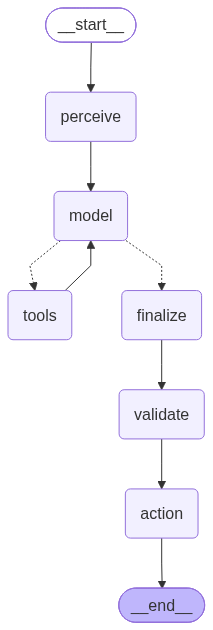

In [24]:
class SingleAgentGraphState(TypedDict):
    reclamacao_id: str
    agent_state: AgentState
    historico: list[Any]
    pending_tool_calls: list[Any]
    raw_decision: dict[str, Any]
    final_output: dict[str, Any]


async def node_single_perceive(state: SingleAgentGraphState) -> dict[str, Any]:
    reclamacao_id = state["reclamacao_id"]
    if not isinstance(reclamacao_id, str) or not re.fullmatch(r"REC\d+", reclamacao_id):
        raise ValueError("ID inválido. Use formato REC001, REC002 etc.")

    ag_state = AgentState(reclamacao_id=reclamacao_id)
    historico = [
        types.Content(
            role="user",
            parts=[
                types.Part.from_text(
                    text=(
                        f"Analise a reclamação {reclamacao_id}. "
                        "Use ferramentas para reunir evidências e conclua quando houver base suficiente."
                    )
                )
            ],
        )
    ]
    return {
        "agent_state": ag_state,
        "historico": historico,
        "pending_tool_calls": [],
    }


async def node_single_model(state: SingleAgentGraphState) -> dict[str, Any]:
    ag_state = state["agent_state"]
    historico = list(state["historico"])

    if (
        ag_state.passo >= MAX_STEPS
        or ag_state.tool_calls >= MAX_TOOL_CALLS
        or ag_state.llm_calls >= MAX_LLM_CALLS
    ):
        return {"pending_tool_calls": []}

    ag_state.passo += 1
    resposta = await gerar_com_retry(
        historico,
        types.GenerateContentConfig(
            system_instruction=SYSTEM_INSTRUCTION,
            tools=[gemini_tools],
            temperature=0.1,
        ),
    )
    ag_state.llm_calls += 1
    conteudo_modelo = resposta.candidates[0].content
    historico.append(conteudo_modelo)

    chamadas = [
        part.function_call
        for part in (conteudo_modelo.parts or [])
        if part.function_call
    ]
    return {
        "agent_state": ag_state,
        "historico": historico,
        "pending_tool_calls": chamadas,
    }


def route_after_model(state: SingleAgentGraphState) -> str:
    if state.get("pending_tool_calls"):
        return "tools"
    return "finalize"


async def node_single_tools(state: SingleAgentGraphState) -> dict[str, Any]:
    ag_state = state["agent_state"]
    historico = list(state["historico"])
    respostas_tools = []

    for chamada in state.get("pending_tool_calls", []):
        nome = chamada.name
        argumentos = dict(chamada.args)
        ag_state.last_action = f"Solicitou {nome} para coletar evidência."
        resultado = await executar_tool_mcp(ag_state, nome, argumentos)
        atualizar_estado(ag_state, nome, resultado)
        respostas_tools.append(
            types.Part.from_function_response(
                name=nome,
                response={"result": resultado},
            )
        )

    if not ag_state.conhecimentos and ag_state.dados_reclamacao:
        consulta_rag = (
            f"{ag_state.dados_reclamacao.get('categoria', '')} "
            f"{ag_state.dados_reclamacao.get('subcategoria', '')} "
            f"{ag_state.dados_reclamacao.get('descricao', '')}"
        )
        ag_state.conhecimentos = rag.buscar(consulta_rag, top_k=RAG_TOP_K)

    historico.append(types.Content(role="user", parts=respostas_tools))
    return {
        "agent_state": ag_state,
        "historico": historico,
        "pending_tool_calls": [],
    }


async def node_single_finalize(state: SingleAgentGraphState) -> dict[str, Any]:
    ag_state = state["agent_state"]
    contexto = json.dumps(
        {
            "reclamacao": ag_state.dados_reclamacao,
            "consumidor": ag_state.consumidor,
            "empresa_produto": ag_state.empresa_produto,
            "pedido": ag_state.pedido,
            "interacoes": ag_state.interacoes,
            "conhecimentos": ag_state.conhecimentos,
        },
        ensure_ascii=False,
        indent=2,
    )
    resposta_final = await gerar_com_retry(
        f"Produza a recomendação final usando exclusivamente as evidências:\n{contexto}",
        types.GenerateContentConfig(
            system_instruction=SYSTEM_INSTRUCTION,
            temperature=0.1,
            response_mime_type="application/json",
            response_json_schema=FINAL_SCHEMA,
        ),
    )
    ag_state.llm_calls += 1
    return {"raw_decision": json.loads(resposta_final.text)}


async def node_single_validate(state: SingleAgentGraphState) -> dict[str, Any]:
    ag_state = state["agent_state"]
    decisao = dict(state["raw_decision"])
    escalonamento = detectar_escalonamento(ag_state)
    decisao["escalonamento_humano"] = bool(
        decisao.get("escalonamento_humano", False) or escalonamento
    )
    jsonschema.validate(instance=decisao, schema=FINAL_SCHEMA)
    return {"raw_decision": decisao}


async def node_single_action(state: SingleAgentGraphState) -> dict[str, Any]:
    ag_state = state["agent_state"]
    final = dict(state["raw_decision"])
    final.update(
        {
            "reclamacao_id": state["reclamacao_id"],
            "ferramentas_usadas": list(dict.fromkeys(ag_state.ferramentas_usadas)),
            "passos_executados": ag_state.passo,
            "chamadas_llm": ag_state.llm_calls,
            "chamadas_ferramentas": ag_state.tool_calls,
            "auditoria": ag_state.auditoria,
        }
    )
    return {"final_output": final}


single_agent_builder = StateGraph(SingleAgentGraphState)
single_agent_builder.add_node("perceive", node_single_perceive)
single_agent_builder.add_node("model", node_single_model)
single_agent_builder.add_node("tools", node_single_tools)
single_agent_builder.add_node("finalize", node_single_finalize)
single_agent_builder.add_node("validate", node_single_validate)
single_agent_builder.add_node("action", node_single_action)

single_agent_builder.add_edge(START, "perceive")
single_agent_builder.add_edge("perceive", "model")
single_agent_builder.add_conditional_edges(
    "model",
    route_after_model,
    {
        "tools": "tools",
        "finalize": "finalize",
    },
)
single_agent_builder.add_edge("tools", "model")
single_agent_builder.add_edge("finalize", "validate")
single_agent_builder.add_edge("validate", "action")
single_agent_builder.add_edge("action", END)

single_agent_graph = single_agent_builder.compile()

print("Grafo da Etapa 1 (Single Agent com LangGraph) compilado com sucesso!")
try:
    display(Image(data=single_agent_graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Fallback Mermaid / ASCII:")
    print(single_agent_graph.get_graph().draw_mermaid())


## 13. Etapa 2 — Arquitetura Multiagente Coordenada (A2A + LangGraph + MCP)

### 13.1. Servidor A2A Multiagente (`servidor_a2a_consumidoria.py`)

A celula abaixo grava o script `servidor_a2a_consumidoria.py` em tempo de execução usando **Starlette**, **Uvicorn** e o SDK oficial `a2a-sdk==1.2.0` na porta `8126` (`http://127.0.0.1:8126`).

O servidor sobe **3 agentes especialistas independentes**, cada um com seu `AgentCard`, `AgentSkill` e executor proprio:

1. **`/knowledge` (`ConsumidorIA Knowledge Agent`)**:
   - Recebe so os dados da queixa (sem dados pessoais do cliente).
   - Consulta os chunks no RAG com embeddings Gemini (ou TF-IDF).
   - Devolve um *Artifact* JSON no formato `KNOWLEDGE_ARTIFACT_SCHEMA`, garantindo q so cita chunks q realmente foram encontrados.
2. **`/operations` (`ConsumidorIA Operations Agent`)**:
   - Recebe o ID da reclamação e o objetivo da busca.
   - Usa o `ClienteMCPConsumidorIA` pra chamar as tools de pedido, consumidor, empresa e interações.
   - Devolve o *Artifact* `OPERATIONS_ARTIFACT_SCHEMA` com os fatos organizados e a trilha de auditoria MCP.
3. **`/strategy` (`ConsumidorIA Strategy Agent`)**:
   - Não acessa nem RAG nem MCP.
   - Recebe os *Artifacts* do Knowledge e do Operations, cruza os fatos com as normas e monta a decisão final no `FINAL_SCHEMA`.

In [29]:
A2A_SERVER_FILE = Path("servidor_a2a_consumidoria.py")

A2A_SERVER_CODE = r'''
from __future__ import annotations

import asyncio
import json
import os
import sys
import time
import uuid
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import uvicorn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from starlette.applications import Starlette

from google import genai
from google.genai import types

from mcp import ClientSession, StdioServerParameters
from mcp.client.stdio import stdio_client

from a2a.helpers.proto_helpers import (
    new_task_from_user_message,
    new_text_message,
    new_text_part,
)
from a2a.server.agent_execution import AgentExecutor, RequestContext
from a2a.server.events.event_queue_v2 import EventQueue
from a2a.server.request_handlers import DefaultRequestHandler
from a2a.server.routes import create_agent_card_routes, create_jsonrpc_routes
from a2a.server.tasks import InMemoryTaskStore, TaskUpdater
from a2a.types import (
    AgentCapabilities,
    AgentCard,
    AgentInterface,
    AgentSkill,
    Role,
)

PORT = 8126
BASE_URL = f"http://127.0.0.1:{PORT}"
LLM_MODEL = "gemini-3.5-flash"
EMBEDDING_MODEL = "gemini-embedding-001"
RAG_TOP_K = 4

GITHUB_USER = "BryanWille"
GITHUB_REPO = "puc_engenharia_agentes-ai-agentica"
GITHUB_BRANCH = "main"
BASE_RAW_DADOS_URL = (
    f"https://raw.githubusercontent.com/"
    f"{GITHUB_USER}/{GITHUB_REPO}/{GITHUB_BRANCH}/dados/"
)

GOOGLE_API_KEY = os.environ.get("GOOGLE_API_KEY", "")
genai_client = genai.Client(api_key=GOOGLE_API_KEY)


def call_gemini_json(prompt: str, system_instruction: str, schema: dict[str, Any]) -> dict[str, Any]:
    last_err = None
    for attempt in range(1, 3):
        try:
            resp = genai_client.models.generate_content(
                model=LLM_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(
                    system_instruction=system_instruction,
                    temperature=0.1,
                    response_mime_type="application/json",
                    response_json_schema=schema,
                ),
            )
            return json.loads(resp.text)
        except Exception as err:
            last_err = err
            time.sleep(1.5 * attempt)
    raise RuntimeError(f"Erro ao chamar Gemini no servidor A2A: {last_err}")


class BaseConhecimentoRAGServer:
    def __init__(self) -> None:
        url = BASE_RAW_DADOS_URL + "base_conhecimento_chunks.csv"
        self.df = pd.read_csv(url, encoding="utf-8")
        self.textos = self.df["texto"].fillna("").astype(str).tolist()
        self.embeddings = None
        self.vectorizer = None
        self.matriz_tfidf = None
        self.tipo_indice = ""
        self._criar_indice()

    def _criar_indice(self) -> None:
        try:
            resposta = genai_client.models.embed_content(
                model=EMBEDDING_MODEL,
                contents=self.textos,
            )
            self.embeddings = np.array(
                [item.values for item in resposta.embeddings],
                dtype=np.float32,
            )
            normas = np.linalg.norm(self.embeddings, axis=1, keepdims=True)
            self.embeddings = self.embeddings / np.where(normas == 0, 1, normas)
            self.tipo_indice = "gemini_embeddings"
        except Exception:
            self.vectorizer = TfidfVectorizer()
            self.matriz_tfidf = self.vectorizer.fit_transform(self.textos)
            self.tipo_indice = "tfidf_fallback"

    def buscar(self, consulta: str, top_k: int = RAG_TOP_K) -> list[dict[str, Any]]:
        consulta = str(consulta).strip()
        if not consulta:
            return []
        try:
            if self.tipo_indice == "gemini_embeddings" and self.embeddings is not None:
                resposta = genai_client.models.embed_content(
                    model=EMBEDDING_MODEL,
                    contents=[consulta],
                )
                vetor = np.array([resposta.embeddings[0].values], dtype=np.float32)
                norma = np.linalg.norm(vetor, axis=1, keepdims=True)
                vetor = vetor / np.where(norma == 0, 1, norma)
                scores = np.dot(self.embeddings, vetor.T).flatten()
            else:
                raise RuntimeError("Usar fallback TF-IDF")
        except Exception:
            if self.vectorizer is None:
                self.vectorizer = TfidfVectorizer()
                self.matriz_tfidf = self.vectorizer.fit_transform(self.textos)
            vetor = self.vectorizer.transform([consulta])
            scores = cosine_similarity(vetor, self.matriz_tfidf).flatten()

        indices = np.argsort(scores)[::-1][:top_k]
        resultados = []
        for indice in indices:
            row = self.df.iloc[int(indice)]
            resultados.append({
                "chunk_id": str(row["chunk_id"]),
                "documento_id": str(row["documento_id"]),
                "titulo": str(row["titulo"]),
                "artigo_secao": str(row["artigo_secao"]),
                "texto": str(row["texto"]),
                "tags": str(row["tags"]),
                "score": round(float(scores[indice]), 4),
            })
        return resultados


class ClienteMCPConsumidorIA:
    def __init__(self, server_file: Path):
        self.server_file = server_file
        self.errlog_path = Path("mcp_server_stderr.log").resolve()

    def _params(self):
        return StdioServerParameters(
            command=sys.executable,
            args=[str(self.server_file.resolve())],
        )

    async def chamar(self, nome: str, argumentos: dict[str, Any]) -> dict[str, Any]:
        with open(self.errlog_path, "a", encoding="utf-8", buffering=1) as errlog:
            async with stdio_client(self._params(), errlog=errlog) as (read, write):
                async with ClientSession(read, write) as session:
                    await session.initialize()
                    resposta = await session.call_tool(nome, arguments=argumentos)
                    textos = [
                        bloco.text
                        for bloco in resposta.content
                        if hasattr(bloco, "text")
                    ]
                    conteudo = "\n".join(textos).strip()
                    try:
                        return json.loads(conteudo)
                    except json.JSONDecodeError:
                        return {"status": "OK", "conteudo": conteudo}


KNOWLEDGE_ARTIFACT_SCHEMA = {
    "type": "object",
    "properties": {
        "resumo_regras": {"type": "string"},
        "regras_chave": {"type": "array", "items": {"type": "string"}},
        "chunks_citados": {"type": "array", "items": {"type": "string"}},
        "evidencias_rag": {"type": "array", "items": {"type": "object"}},
    },
    "required": ["resumo_regras", "regras_chave", "chunks_citados", "evidencias_rag"],
}

OPERATIONS_ARTIFACT_SCHEMA = {
    "type": "object",
    "properties": {
        "consumidor": {"type": "object"},
        "pedido": {"type": "object"},
        "empresa_produto": {"type": "object"},
        "interacoes": {"type": "array", "items": {"type": "object"}},
        "ferramentas_mcp_usadas": {"type": "array", "items": {"type": "string"}},
        "auditoria_mcp": {"type": "array", "items": {"type": "object"}},
    },
    "required": [
        "consumidor",
        "pedido",
        "empresa_produto",
        "interacoes",
        "ferramentas_mcp_usadas",
        "auditoria_mcp",
    ],
}

FINAL_SCHEMA = {
    "type": "object",
    "properties": {
        "resumo_caso": {"type": "string"},
        "categoria": {"type": "string"},
        "subcategoria": {"type": "string"},
        "prioridade": {"type": "string"},
        "evidencias_consultadas": {"type": "array", "items": {"type": "string"}},
        "fundamento": {"type": "string"},
        "decisao": {
            "type": "string",
            "enum": ["PROCEDENTE", "PARCIALMENTE_PROCEDENTE", "IMPROCEDENTE", "INCONCLUSIVO"],
        },
        "acao_recomendada": {"type": "string"},
        "prazo_dias": {"type": "integer"},
        "escalonamento_humano": {"type": "boolean"},
        "limitacoes": {"type": "array", "items": {"type": "string"}},
    },
    "required": [
        "resumo_caso",
        "categoria",
        "subcategoria",
        "prioridade",
        "evidencias_consultadas",
        "fundamento",
        "decisao",
        "acao_recomendada",
        "prazo_dias",
        "escalonamento_humano",
        "limitacoes",
    ],
}

rag_engine = BaseConhecimentoRAGServer()
mcp_client = ClienteMCPConsumidorIA(Path("consumidoria_mcp_server.py"))


class KnowledgeAgentExecutor(AgentExecutor):
    async def execute(self, context: RequestContext, event_queue: EventQueue) -> None:
        task = context.current_task
        if task is None:
            task = new_task_from_user_message(context.message)
            await event_queue.enqueue_event(task)

        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work(
            new_text_message(
                "KnowledgeAgent consultando base normativa via Vector RAG...",
                role=Role.ROLE_AGENT,
                context_id=task.context_id,
                task_id=task.id,
            )
        )

        payload = json.loads(context.get_user_input() or "{}")
        req = payload.get("request", {})
        objective = payload.get("objective", "Identificar regras e prazos aplicáveis.")

        consulta = (
            f"{req.get('categoria', '')} {req.get('subcategoria', '')} "
            f"{req.get('descricao', '')} {objective}"
        ).strip() or "classificação prazos direitos consumidor escalonamento"

        chunks = rag_engine.buscar(consulta, top_k=RAG_TOP_K)
        ids_validos = {c["chunk_id"] for c in chunks}

        llm_schema = {
            "type": "object",
            "properties": {
                "resumo_regras": {"type": "string"},
                "regras_chave": {"type": "array", "items": {"type": "string"}},
                "chunks_citados": {"type": "array", "items": {"type": "string"}},
            },
            "required": ["resumo_regras", "regras_chave", "chunks_citados"],
        }

        prompt = (
            f"Objetivo: {objective}\n"
            f"Dados normativos da disputa (sem PII): {json.dumps(req, ensure_ascii=False)}\n"
            f"Chunks recuperados no Vector RAG: {json.dumps(chunks, ensure_ascii=False)}\n\n"
            "Sintetize as regras institucionais e artigos/seções aplicáveis. "
            "Cite apenas chunk_ids presentes na lista recuperada."
        )

        sintese = await asyncio.to_thread(
            call_gemini_json,
            prompt,
            "Você é o KnowledgeAgent normativo do ConsumidorIA. Use estritamente os chunks fornecidos.",
            llm_schema,
        )

        chunks_filtrados = [cid for cid in sintese.get("chunks_citados", []) if cid in ids_validos]
        if not chunks_filtrados and chunks:
            chunks_filtrados = [chunks[0]["chunk_id"]]

        artifact_data = {
            "resumo_regras": sintese.get("resumo_regras", ""),
            "regras_chave": sintese.get("regras_chave", []),
            "chunks_citados": chunks_filtrados,
            "evidencias_rag": chunks,
        }

        await updater.add_artifact(
            parts=[new_text_part(json.dumps(artifact_data, ensure_ascii=False))],
            name="knowledge_artifact",
        )
        await updater.complete(
            new_text_message(
                "Análise normativa concluída com sucesso.",
                role=Role.ROLE_AGENT,
                context_id=task.context_id,
                task_id=task.id,
            )
        )

    async def cancel(self, context: RequestContext, event_queue: EventQueue) -> None:
        updater = TaskUpdater(event_queue, context.task_id, context.context_id)
        await updater.cancel()


class OperationsAgentExecutor(AgentExecutor):
    async def execute(self, context: RequestContext, event_queue: EventQueue) -> None:
        task = context.current_task
        if task is None:
            task = new_task_from_user_message(context.message)
            await event_queue.enqueue_event(task)

        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work(
            new_text_message(
                "OperationsAgent consultando sistemas operacionais via MCP...",
                role=Role.ROLE_AGENT,
                context_id=task.context_id,
                task_id=task.id,
            )
        )

        payload = json.loads(context.get_user_input() or "{}")
        req = payload.get("request", {})
        reclamacao_id = req.get("reclamacao_id", "")
        consumidor_id = req.get("consumidor_id", "")
        pedido_id = req.get("pedido_id", "")
        empresa_id = req.get("empresa_id", "")

        ferramentas_usadas: list[str] = []
        auditoria_mcp: list[dict[str, Any]] = []

        async def call_mcp_logged(tool_name: str, args: dict[str, Any], motivo: str) -> dict[str, Any]:
            t0 = time.time()
            try:
                res = await mcp_client.chamar(tool_name, args)
                status = "SUCESSO" if res.get("status") != "ERRO" else "ERRO"
            except Exception as exc:
                res = {"status": "ERRO", "mensagem": str(exc)}
                status = "ERRO"
            duracao_ms = int((time.time() - t0) * 1000)
            ferramentas_usadas.append(tool_name)
            auditoria_mcp.append({
                "execucao_id": str(uuid.uuid4()),
                "reclamacao_id": reclamacao_id,
                "passo": 2,
                "pensamento_resumo": f"[OperationsAgent via MCP] {motivo}",
                "ferramenta": tool_name,
                "argumentos_json": json.dumps(args, ensure_ascii=False),
                "resultado_resumo": json.dumps(res, ensure_ascii=False)[:600],
                "status": status,
                "duracao_ms": duracao_ms,
                "erro": res.get("mensagem", "") if status != "SUCESSO" else "",
            })
            return res

        if req.get("status") == "OK":
            consumidor = await call_mcp_logged(
                "consultar_consumidor",
                {"consumidor_id": consumidor_id},
                "Consultar dados mínimos do consumidor (CPF mascarado).",
            )
            pedido = await call_mcp_logged(
                "consultar_pedido",
                {"pedido_id": pedido_id},
                "Consultar pedido, entrega, pagamento e garantia.",
            )
            produto_id = pedido.get("produto_id", "") if pedido.get("status") == "OK" else ""
            empresa_produto = await call_mcp_logged(
                "consultar_empresa_produto",
                {"empresa_id": empresa_id, "produto_id": produto_id},
                "Consultar SLA da empresa e dados do produto/serviço.",
            )
            interacoes_res = await call_mcp_logged(
                "consultar_interacoes",
                {"reclamacao_id": reclamacao_id},
                "Consultar histórico de interações e anexos no SAC.",
            )
            interacoes = interacoes_res.get("interacoes", []) if interacoes_res.get("status") == "OK" else []
        else:
            interacoes_res = await call_mcp_logged(
                "consultar_interacoes",
                {"reclamacao_id": reclamacao_id},
                "Verificar existência de interações para o ID informado.",
            )
            consumidor = {"status": "ERRO", "mensagem": "Reclamação inexistente; consumidor não vinculado."}
            pedido = {"status": "ERRO", "mensagem": "Reclamação inexistente; pedido não vinculado."}
            empresa_produto = {"status": "ERRO", "mensagem": "Reclamação inexistente; empresa não vinculada."}
            interacoes = interacoes_res.get("interacoes", [])

        artifact_data = {
            "consumidor": consumidor,
            "pedido": pedido,
            "empresa_produto": empresa_produto,
            "interacoes": interacoes,
            "ferramentas_mcp_usadas": ferramentas_usadas,
            "auditoria_mcp": auditoria_mcp,
        }

        await updater.add_artifact(
            parts=[new_text_part(json.dumps(artifact_data, ensure_ascii=False))],
            name="operations_artifact",
        )
        await updater.complete(
            new_text_message(
                "Coleta operacional via MCP concluída.",
                role=Role.ROLE_AGENT,
                context_id=task.context_id,
                task_id=task.id,
            )
        )

    async def cancel(self, context: RequestContext, event_queue: EventQueue) -> None:
        updater = TaskUpdater(event_queue, context.task_id, context.context_id)
        await updater.cancel()


class StrategyAgentExecutor(AgentExecutor):
    async def execute(self, context: RequestContext, event_queue: EventQueue) -> None:
        task = context.current_task
        if task is None:
            task = new_task_from_user_message(context.message)
            await event_queue.enqueue_event(task)

        updater = TaskUpdater(event_queue, task.id, task.context_id)
        await updater.start_work(
            new_text_message(
                "StrategyAgent consolidando Artifacts de Knowledge e Operations...",
                role=Role.ROLE_AGENT,
                context_id=task.context_id,
                task_id=task.id,
            )
        )

        payload = json.loads(context.get_user_input() or "{}")
        req = payload.get("request", {})
        objective = payload.get("objective", "Emitir recomendação estruturada no FINAL_SCHEMA.")
        specialists = payload.get("specialist_results", {})

        prompt = f"""
Objetivo: {objective}

Dados da Reclamação (Intake):
{json.dumps(req, ensure_ascii=False, indent=2)}

Artifact do KnowledgeAgent (Regras e Chunks RAG):
{json.dumps(specialists.get("knowledge", {}), ensure_ascii=False, indent=2)}

Artifact do OperationsAgent (Fatos via MCP):
{json.dumps(specialists.get("operations", {}), ensure_ascii=False, indent=2)}

Regras obrigatórias de síntese:
1. Use exclusivamente os Artifacts recebidos (você não tem RAG nem MCP).
2. Se a reclamação não foi encontrada (status=ERRO) ou se faltarem documentos/evidências essenciais (ex.: status_reclamacao AGUARDANDO_DOCUMENTOS ou ausência de comprovante/foto necessária), defina decisao como "INCONCLUSIVO".
3. Quando houver evidência clara de defeito no prazo, atraso injustificado, serviço instável ou cobrança indevida comprovada, recomende a resolução apropriada ("PROCEDENTE" ou "PARCIALMENTE_PROCEDENTE").
4. Cite em evidencias_consultadas os IDs reais consultados (ex.: pedido, interações, chunk_ids do KnowledgeAgent).
5. Caso de valor > R$ 5.000 ou risco/fraude deve ter escalonamento_humano = true.
"""

        parecer = await asyncio.to_thread(
            call_gemini_json,
            prompt,
            "Você é o StrategyAgent do ConsumidorIA. Sintetize os artefatos normativo e operacional no FINAL_SCHEMA.",
            FINAL_SCHEMA,
        )

        if req.get("status") == "ERRO":
            parecer["decisao"] = "INCONCLUSIVO"

        await updater.add_artifact(
            parts=[new_text_part(json.dumps(parecer, ensure_ascii=False))],
            name="strategy_artifact",
        )
        await updater.complete(
            new_text_message(
                "Parecer estratégico emitido com sucesso.",
                role=Role.ROLE_AGENT,
                context_id=task.context_id,
                task_id=task.id,
            )
        )

    async def cancel(self, context: RequestContext, event_queue: EventQueue) -> None:
        updater = TaskUpdater(event_queue, context.task_id, context.context_id)
        await updater.cancel()


knowledge_card = AgentCard(
    name="ConsumidorIA Knowledge Agent",
    description=(
        "Especialista normativo que consulta políticas institucionais, manual de análise "
        "e guia de direitos do consumidor via Vector RAG (sem acesso a MCP ou PII)."
    ),
    version="1.0.0",
    supported_interfaces=[
        AgentInterface(
            protocol_binding="JSONRPC",
            protocol_version="1.0",
            url=f"{BASE_URL}/knowledge",
        )
    ],
    capabilities=AgentCapabilities(streaming=True),
    default_input_modes=["text/plain", "application/json"],
    default_output_modes=["text/plain", "application/json"],
    skills=[
        AgentSkill(
            id="normative_rag_analysis",
            name="Análise Normativa via Vector RAG",
            description="Recupera chunks normativos do CDC e políticas internas aplicáveis à disputa.",
            tags=["rag", "normas", "cdc", "politicas"],
        )
    ],
)

operations_card = AgentCard(
    name="ConsumidorIA Operations Agent",
    description=(
        "Especialista operacional que consulta consumidor (CPF mascarado), pedido, "
        "empresa/produto e histórico de interações do SAC via servidor MCP."
    ),
    version="1.0.0",
    supported_interfaces=[
        AgentInterface(
            protocol_binding="JSONRPC",
            protocol_version="1.0",
            url=f"{BASE_URL}/operations",
        )
    ],
    capabilities=AgentCapabilities(streaming=True),
    default_input_modes=["text/plain", "application/json"],
    default_output_modes=["text/plain", "application/json"],
    skills=[
        AgentSkill(
            id="operational_mcp_lookup",
            name="Levantamento Operacional via MCP",
            description="Consulta fatos operacionais da reclamação (consumidor, pedido, garantia, SAC) via MCP.",
            tags=["mcp", "operacoes", "pedido", "sac"],
        )
    ],
)

strategy_card = AgentCard(
    name="ConsumidorIA Strategy Agent",
    description=(
        "Especialista de parecer final que cruza os Artifacts normativo (Knowledge) e "
        "operacional (Operations) para emitir recomendação segundo o FINAL_SCHEMA."
    ),
    version="1.0.0",
    supported_interfaces=[
        AgentInterface(
            protocol_binding="JSONRPC",
            protocol_version="1.0",
            url=f"{BASE_URL}/strategy",
        )
    ],
    capabilities=AgentCapabilities(streaming=True),
    default_input_modes=["text/plain", "application/json"],
    default_output_modes=["text/plain", "application/json"],
    skills=[
        AgentSkill(
            id="dispute_strategy_synthesis",
            name="Síntese de Recomendação e Parecer",
            description="Consolida regras e fatos operacionais em recomendação auditável no FINAL_SCHEMA.",
            tags=["estrategia", "parecer", "decisao"],
        )
    ],
)

routes = []
for prefix, card, executor in [
    ("/knowledge", knowledge_card, KnowledgeAgentExecutor()),
    ("/operations", operations_card, OperationsAgentExecutor()),
    ("/strategy", strategy_card, StrategyAgentExecutor()),
]:
    handler = DefaultRequestHandler(
        agent_executor=executor,
        task_store=InMemoryTaskStore(),
        agent_card=card,
    )
    routes.extend(
        create_agent_card_routes(
            agent_card=card,
            card_url=f"{prefix}/.well-known/agent-card.json",
        )
    )
    routes.extend(
        create_jsonrpc_routes(
            request_handler=handler,
            rpc_url=prefix,
        )
    )

app = Starlette(routes=routes)

if __name__ == "__main__":
    uvicorn.run(app, host="127.0.0.1", port=PORT, log_level="warning")
'''

A2A_SERVER_FILE.write_text(A2A_SERVER_CODE, encoding="utf-8")
print("Script do servidor A2A gravado com sucesso:")
print(A2A_SERVER_FILE.resolve())


Script do servidor A2A gravado com sucesso:
C:\git\puc_engenharia_agentes-ai-agentica\servidor_a2a_consumidoria.py


### 13.2. Subprocesso A2A, Discovery de *Agent Cards* e `A2AAgentClient`

Aqui a gente sobe o `servidor_a2a_consumidoria.py` em segundo plano com `subprocess.Popen`, espera os 3 endpoints responderem (`esperar_agent_cards()`) e faz o discovery dinamico dos *Agent Cards* com `A2ACardResolver`. 

Depois, o `A2AAgentClient` gerencia o envio de tarefas com `SendMessageRequest` e acompanha todo o ciclo de vida da `Task` (`SUBMITTED` → `WORKING` → `COMPLETED`) ate pegar o *Artifact* final.

In [30]:
from a2a.client import A2ACardResolver, ClientConfig, create_client
from a2a.helpers.proto_helpers import get_artifact_text, new_text_message
from a2a.types import AgentCard, Role, SendMessageRequest, TaskState

A2A_BASE_URL = "http://127.0.0.1:8126"
A2A_AGENT_ENDPOINTS = {
    "knowledge": f"{A2A_BASE_URL}/knowledge",
    "operations": f"{A2A_BASE_URL}/operations",
    "strategy": f"{A2A_BASE_URL}/strategy",
}

if "processo_a2a" in globals() and processo_a2a is not None:
    try:
        processo_a2a.terminate()
        processo_a2a.wait(timeout=3)
    except Exception:
        pass

a2a_log_file = open("a2a_server.log", "w", encoding="utf-8")
processo_a2a = subprocess.Popen(
    [sys.executable, str(A2A_SERVER_FILE.resolve())],
    stdout=a2a_log_file,
    stderr=subprocess.STDOUT,
    env=os.environ.copy(),
)


async def esperar_agent_cards(timeout_s: float = 45.0) -> None:
    inicio = time.time()
    async with httpx.AsyncClient(timeout=5.0) as http_client:
        while time.time() - inicio < timeout_s:
            prontos = 0
            for url in A2A_AGENT_ENDPOINTS.values():
                try:
                    resp = await http_client.get(f"{url}/.well-known/agent-card.json")
                    if resp.status_code == 200:
                        prontos += 1
                except Exception:
                    pass
            if prontos == len(A2A_AGENT_ENDPOINTS):
                print(f"✓ Servidor A2A pronto em {A2A_BASE_URL} ({prontos} agentes ativos).")
                return
            await asyncio.sleep(0.5)

    logs = Path("a2a_server.log").read_text(encoding="utf-8") if Path("a2a_server.log").exists() else ""
    raise RuntimeError(f"Timeout aguardando servidor A2A.\nLogs:\n{logs}")


async def descobrir_cards() -> dict[str, AgentCard]:
    cards: dict[str, AgentCard] = {}
    async with httpx.AsyncClient(timeout=10.0) as http_client:
        for chave, base_url in A2A_AGENT_ENDPOINTS.items():
            resolver = A2ACardResolver(httpx_client=http_client, base_url=base_url)
            card = await resolver.get_agent_card()
            cards[chave] = card
    return cards


class A2AAgentClient:
    """Cliente A2A que encapsula create_client, SendMessageRequest e rastreio de ciclo de vida da Task."""

    def __init__(self, agent_key: str, card: AgentCard):
        self.agent_key = agent_key
        self.card = card
        self._httpx_client: httpx.AsyncClient | None = None
        self._client = None

    async def _ensure_client(self):
        if self._client is None:
            self._httpx_client = httpx.AsyncClient(timeout=60.0)
            config = ClientConfig(
                streaming=True,
                httpx_client=self._httpx_client,
            )
            self._client = await create_client(self.card, client_config=config)
        return self._client

    async def enviar_tarefa(
        self,
        payload: dict[str, Any],
        context_id: str,
        verbose: bool = True,
    ) -> dict[str, Any]:
        client_a2a = await self._ensure_client()
        mensagem = new_text_message(
            text=json.dumps(payload, ensure_ascii=False),
            role=Role.ROLE_USER,
            context_id=context_id,
        )
        request = SendMessageRequest(message=mensagem)

        artifact_json: dict[str, Any] = {}
        task_id_atual = ""
        estados_vistos: list[str] = []

        async for event in client_a2a.send_message(request):
            if event.HasField("task"):
                task_obj = event.task
                task_id_atual = task_obj.id
                nome_estado = TaskState.Name(task_obj.status.state)
                estados_vistos.append(nome_estado)
                if verbose:
                    print(f"  [A2A:{self.agent_key}] Task {task_id_atual[:8]}... -> {nome_estado}")
                for art in task_obj.artifacts:
                    texto_art = get_artifact_text(art)
                    if texto_art:
                        artifact_json = json.loads(texto_art)
                        if verbose:
                            print(f"  [A2A:{self.agent_key}] Task {task_id_atual[:8]}... -> ARTIFACT ({art.name})")

            elif event.HasField("status_update"):
                upd = event.status_update
                task_id_atual = upd.task_id or task_id_atual
                nome_estado = TaskState.Name(upd.status.state)
                estados_vistos.append(nome_estado)
                if verbose:
                    print(f"  [A2A:{self.agent_key}] Task {task_id_atual[:8]}... -> {nome_estado}")

            elif event.HasField("artifact_update"):
                art_upd = event.artifact_update
                task_id_atual = art_upd.task_id or task_id_atual
                texto_art = get_artifact_text(art_upd.artifact)
                if texto_art:
                    artifact_json = json.loads(texto_art)
                    if verbose:
                        print(f"  [A2A:{self.agent_key}] Task {task_id_atual[:8]}... -> ARTIFACT ({art_upd.artifact.name})")

            elif event.HasField("message"):
                pass

        return {
            "agent": self.agent_key,
            "task_id": task_id_atual,
            "context_id": context_id,
            "lifecycle": estados_vistos,
            "artifact": artifact_json,
        }

    async def close(self) -> None:
        if self._client is not None:
            await self._client.close()
            self._client = None
        if self._httpx_client is not None:
            await self._httpx_client.aclose()
            self._httpx_client = None


await esperar_agent_cards()
AGENT_CARDS = await descobrir_cards()
A2A_CLIENTS = {
    chave: A2AAgentClient(chave, card)
    for chave, card in AGENT_CARDS.items()
}

print("\nAgent Cards descobertos via A2ACardResolver:")
for chave, card in AGENT_CARDS.items():
    iface = card.supported_interfaces[0]
    skills = [f"{s.id} ({s.name})" for s in card.skills]
    print(f"- [{chave}] {card.name} v{card.version}")
    print(f"  URL: {iface.url} | Binding: {iface.protocol_binding} v{iface.protocol_version}")
    print(f"  Descrição: {card.description}")
    print(f"  Skills: {skills}")


✓ Servidor A2A pronto em http://127.0.0.1:8126 (3 agentes ativos).

Agent Cards descobertos via A2ACardResolver:
- [knowledge] ConsumidorIA Knowledge Agent v1.0.0
  URL: http://127.0.0.1:8126/knowledge | Binding: JSONRPC v1.0
  Descrição: Especialista normativo que consulta políticas institucionais, manual de análise e guia de direitos do consumidor via Vector RAG (sem acesso a MCP ou PII).
  Skills: ['normative_rag_analysis (Análise Normativa via Vector RAG)']
- [operations] ConsumidorIA Operations Agent v1.0.0
  URL: http://127.0.0.1:8126/operations | Binding: JSONRPC v1.0
  Descrição: Especialista operacional que consulta consumidor (CPF mascarado), pedido, empresa/produto e histórico de interações do SAC via servidor MCP.
  Skills: ['operational_mcp_lookup (Levantamento Operacional via MCP)']
- [strategy] ConsumidorIA Strategy Agent v1.0.0
  URL: http://127.0.0.1:8126/strategy | Binding: JSONRPC v1.0
  Descrição: Especialista de parecer final que cruza os Artifacts normativo (Knowl

### 13.3. Orquestrador Multiagente (`StateGraph` do Supervisor)

Montamos o `multiagent_graph` com `StateGraph(MultiAgentState)` contendo os 4 passos principais da coordenação:
1. **`perceive_intake` (Deterministico):** valida se o ID bate com `r"REC\d+"` (da erro se tiver errado) e faz a primeira leitura da reclamação via MCP.
2. **`supervisor_plan` (Planejador com LLM):** le os *Agent Cards* descobertos e os *Artifacts* q ja chegaram, decidindo a proxima onda com base no `SUPERVISOR_DECISION_SCHEMA`:
   - **Onda 1:** manda ao mesmo tempo pro `knowledge` e pro `operations`;
   - **Onda 2:** com os dados na mao, manda pro `strategy`;
   - **Fim:** encerra o fluxo (`finish`).
3. **`delegate_a2a` (Execução Paralela A2A):** dispara os agentes da rodada juntos usando `asyncio.gather`, grava os tempos e salva os *Artifacts* no estado.
4. **`validate_and_finalize` (Deterministico — Governança):** pega o parecer do Strategy, aplica a trava de R$ 5.000 / risco alto via `detectar_escalonamento()`, valida o `FINAL_SCHEMA` e consolida a tabela de auditoria completa.

Grafo Multiagente do Supervisor (Etapa 2) compilado com sucesso!


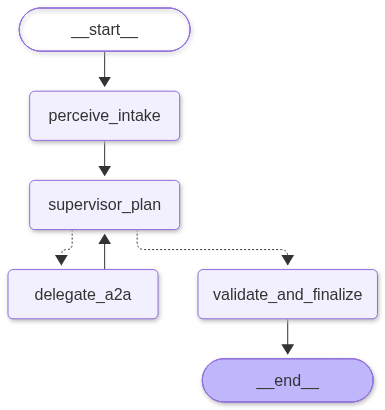

In [31]:
class MultiAgentState(TypedDict):
    reclamacao_id: str
    a2a_context_id: str
    dados_reclamacao: dict[str, Any]
    agent_catalog: dict[str, Any]
    agentes_acionados: list[str]
    specialist_artifacts: dict[str, Any]
    routing_log: list[dict[str, Any]]
    execution_waves: list[dict[str, Any]]
    current_decision: dict[str, Any]
    auditoria: list[dict[str, Any]]
    ferramentas_usadas: list[str]
    passos_executados: int
    chamadas_llm: int
    chamadas_ferramentas: int
    final_output: dict[str, Any]


def montar_catalogo_cards() -> dict[str, Any]:
    catalogo = {}
    for chave, card in AGENT_CARDS.items():
        catalogo[chave] = {
            "name": card.name,
            "description": card.description,
            "skills": [{"id": s.id, "name": s.name, "description": s.description} for s in card.skills],
        }
    return catalogo


async def node_perceive_intake(state: MultiAgentState) -> dict[str, Any]:
    reclamacao_id = state["reclamacao_id"]
    if not isinstance(reclamacao_id, str) or not re.fullmatch(r"REC\d+", reclamacao_id):
        raise ValueError("ID inválido. Use formato REC001, REC002 etc.")

    t0 = time.time()
    dados_rec = await cliente_mcp.chamar("consultar_reclamacao", {"reclamacao_id": reclamacao_id})
    duracao_ms = int((time.time() - t0) * 1000)
    status_mcp = "SUCESSO" if dados_rec.get("status") != "ERRO" else "ERRO"

    auditoria_intake = [
        {
            "execucao_id": str(uuid.uuid4()),
            "reclamacao_id": reclamacao_id,
            "passo": 1,
            "pensamento_resumo": "[Supervisor perceive_intake] Validação determinística do ID e intake da reclamação via MCP.",
            "ferramenta": "consultar_reclamacao",
            "argumentos_json": json.dumps({"reclamacao_id": reclamacao_id}, ensure_ascii=False),
            "resultado_resumo": json.dumps(dados_rec, ensure_ascii=False)[:600],
            "status": status_mcp,
            "duracao_ms": duracao_ms,
            "erro": dados_rec.get("mensagem", "") if status_mcp != "SUCESSO" else "",
        }
    ]

    return {
        "a2a_context_id": str(uuid.uuid4()),
        "dados_reclamacao": dados_rec,
        "agent_catalog": montar_catalogo_cards(),
        "agentes_acionados": [],
        "specialist_artifacts": {},
        "routing_log": [],
        "execution_waves": [],
        "current_decision": {},
        "auditoria": auditoria_intake,
        "ferramentas_usadas": ["consultar_reclamacao"],
        "passos_executados": 1,
        "chamadas_llm": 0,
        "chamadas_ferramentas": 1,
    }


async def node_supervisor_plan(state: MultiAgentState) -> dict[str, Any]:
    artifacts = state.get("specialist_artifacts", {})
    acionados = list(state.get("agentes_acionados", []))
    passo_atual = state.get("passos_executados", 1) + 1
    llm_calls = state.get("chamadas_llm", 0)

    prompt_supervisor = f"""
Você é o SupervisorAgent coordenador do ConsumidorIA.
Catálogo de Especialistas A2A descobertos via Agent Cards:
{json.dumps(state.get("agent_catalog", {}), ensure_ascii=False, indent=2)}

Reclamação (Intake):
{json.dumps(state.get("dados_reclamacao", {}), ensure_ascii=False)}

Agentes já acionados: {acionados}
Artifacts já coletados no estado: {list(artifacts.keys())}

Regras de orquestração em ondas:
- Se 'knowledge' e 'operations' ainda não foram executados, delegue AMBOS simultaneamente (action="delegate") para investigação paralela na Onda 1.
- Se 'knowledge' e 'operations' já produziram Artifacts mas 'strategy' ainda não foi executado, delegue para 'strategy' (action="delegate") na Onda 2.
- Se 'strategy' já produziu seu Artifact, encerre o fluxo (action="finish", delegations=[]).
"""

    try:
        resp = await gerar_com_retry(
            prompt_supervisor,
            types.GenerateContentConfig(
                system_instruction="Supervisor Multiagente A2A. Planeje as delegações conforme os Agent Cards e Artifacts presentes.",
                temperature=0.0,
                response_mime_type="application/json",
                response_json_schema=SUPERVISOR_DECISION_SCHEMA,
            ),
        )
        llm_calls += 1
        decisao = json.loads(resp.text)
    except Exception:
        decisao = {"action": "finish", "routing_reason": "Fallback determinístico.", "delegations": []}

    # Garantia determinística da política de ondas do Supervisor
    if "knowledge" not in artifacts or "operations" not in artifacts:
        decisao = {
            "action": "delegate",
            "routing_reason": decisao.get("routing_reason")
            or "Onda 1 Paralela: knowledge (regras RAG sem PII) e operations (fatos MCP) são independentes e executam simultaneamente.",
            "delegations": [
                {
                    "agent": "knowledge",
                    "objective": "Recuperar normas, prazos e diretrizes do CDC/políticas aplicáveis à categoria e descrição da disputa.",
                },
                {
                    "agent": "operations",
                    "objective": "Levantar fatos operacionais do caso via MCP (consumidor com CPF mascarado, pedido, empresa/produto e SAC).",
                },
            ],
        }
    elif "strategy" not in artifacts:
        decisao = {
            "action": "delegate",
            "routing_reason": decisao.get("routing_reason")
            or "Onda 2 Sequencial: consolidar Artifacts de knowledge e operations no StrategyAgent para emitir recomendação no FINAL_SCHEMA.",
            "delegations": [
                {
                    "agent": "strategy",
                    "objective": "Cruzar regras normativas e fatos operacionais para produzir o parecer final estruturado.",
                }
            ],
        }
    else:
        decisao = {
            "action": "finish",
            "routing_reason": decisao.get("routing_reason")
            or "Ciclo 3: Artifacts de knowledge, operations e strategy concluídos; prosseguir para validação e governança final.",
            "delegations": [],
        }

    novo_log = list(state.get("routing_log", []))
    novo_log.append(
        {
            "cycle": len(novo_log) + 1,
            "action": decisao["action"],
            "agents": [d["agent"] for d in decisao.get("delegations", [])],
            "routing_reason": decisao["routing_reason"],
        }
    )

    return {
        "current_decision": decisao,
        "routing_log": novo_log,
        "passos_executados": passo_atual,
        "chamadas_llm": llm_calls,
    }


def route_supervisor(state: MultiAgentState) -> str:
    if state.get("current_decision", {}).get("action") == "delegate":
        return "delegate_a2a"
    return "validate_and_finalize"


async def node_delegate_a2a(state: MultiAgentState) -> dict[str, Any]:
    decisao = state["current_decision"]
    delegations = decisao.get("delegations", [])
    context_id = state["a2a_context_id"]
    dados_rec = state["dados_reclamacao"]
    artifacts = dict(state.get("specialist_artifacts", {}))
    acionados = list(state.get("agentes_acionados", []))
    waves = list(state.get("execution_waves", []))
    auditoria = list(state.get("auditoria", []))
    ferramentas = list(state.get("ferramentas_usadas", []))
    passo_atual = state.get("passos_executados", 2)
    chamadas_llm = state.get("chamadas_llm", 0)
    chamadas_tools = state.get("chamadas_ferramentas", 1)

    wave_number = len(waves) + 1
    wave_agents = [d["agent"] for d in delegations]
    print(f"\n>>> [Supervisor] Iniciando Onda {wave_number} via A2A (paralelo={len(wave_agents) > 1}): {wave_agents}")

    async def call_specialist(d: dict[str, str]) -> dict[str, Any]:
        agent_key = d["agent"]
        objective = d["objective"]
        t_start = time.time()

        if agent_key == "knowledge":
            # Menor privilégio (LGPD): KnowledgeAgent recebe apenas metadados normativos da disputa, sem PII
            req_payload = {
                "reclamacao_id": dados_rec.get("reclamacao_id", state["reclamacao_id"]),
                "categoria": dados_rec.get("categoria", ""),
                "subcategoria": dados_rec.get("subcategoria", ""),
                "descricao": dados_rec.get("descricao", ""),
                "prioridade": dados_rec.get("prioridade", ""),
                "status_reclamacao": dados_rec.get("status_reclamacao", ""),
            }
            payload = {"request": req_payload, "objective": objective}
        elif agent_key == "operations":
            payload = {"request": dados_rec, "objective": objective}
        else:
            payload = {
                "request": dados_rec,
                "objective": objective,
                "specialist_results": {
                    "knowledge": artifacts.get("knowledge", {}),
                    "operations": artifacts.get("operations", {}),
                },
            }

        res_a2a = await A2A_CLIENTS[agent_key].enviar_tarefa(payload, context_id=context_id, verbose=True)
        elapsed_ms = int((time.time() - t_start) * 1000)
        res_a2a["duracao_ms"] = elapsed_ms
        res_a2a["objective"] = objective
        return res_a2a

    t_wave = time.time()
    resultados_onda = await asyncio.gather(*(call_specialist(d) for d in delegations))
    wave_duration_ms = int((time.time() - t_wave) * 1000)

    for res in resultados_onda:
        ag = res["agent"]
        art = res["artifact"]
        if ag == "knowledge":
            jsonschema.validate(instance=art, schema=KNOWLEDGE_ARTIFACT_SCHEMA)
            chamadas_llm += 1
            ferramentas.append("consultar_base_conhecimento")
        elif ag == "operations":
            jsonschema.validate(instance=art, schema=OPERATIONS_ARTIFACT_SCHEMA)
            for mcp_tool in art.get("ferramentas_mcp_usadas", []):
                ferramentas.append(mcp_tool)
            for item_audit in art.get("auditoria_mcp", []):
                auditoria.append(item_audit)
                chamadas_tools += 1
        elif ag == "strategy":
            jsonschema.validate(instance=art, schema=FINAL_SCHEMA)
            chamadas_llm += 1

        artifacts[ag] = art
        if ag not in acionados:
            acionados.append(ag)

        auditoria.append(
            {
                "execucao_id": res["task_id"] or str(uuid.uuid4()),
                "reclamacao_id": state["reclamacao_id"],
                "passo": passo_atual,
                "pensamento_resumo": f"[Supervisor -> A2A:{ag}] {res['objective']}",
                "ferramenta": f"a2a:{ag}",
                "argumentos_json": json.dumps(
                    {"agent": ag, "context_id": context_id, "lifecycle": res["lifecycle"]},
                    ensure_ascii=False,
                ),
                "resultado_resumo": json.dumps(art, ensure_ascii=False)[:600],
                "status": "SUCESSO",
                "duracao_ms": res["duracao_ms"],
                "erro": "",
            }
        )

    waves.append(
        {
            "wave": wave_number,
            "agents": wave_agents,
            "parallel": len(wave_agents) > 1,
            "duration_ms": wave_duration_ms,
        }
    )

    return {
        "specialist_artifacts": artifacts,
        "agentes_acionados": acionados,
        "execution_waves": waves,
        "auditoria": auditoria,
        "ferramentas_usadas": list(dict.fromkeys(ferramentas)),
        "chamadas_llm": chamadas_llm,
        "chamadas_ferramentas": chamadas_tools,
    }


async def node_validate_and_finalize(state: MultiAgentState) -> dict[str, Any]:
    dados_rec = state["dados_reclamacao"]
    strategy_artifact = dict(state["specialist_artifacts"]["strategy"])

    escalonamento_obrigatorio = detectar_escalonamento(dados_rec)
    strategy_artifact["escalonamento_humano"] = bool(
        strategy_artifact.get("escalonamento_humano", False) or escalonamento_obrigatorio
    )

    if dados_rec.get("status") == "ERRO":
        strategy_artifact["decisao"] = "INCONCLUSIVO"

    jsonschema.validate(instance=strategy_artifact, schema=FINAL_SCHEMA)

    final_output = dict(strategy_artifact)
    final_output.update(
        {
            "reclamacao_id": state["reclamacao_id"],
            "agentes_acionados": list(state["agentes_acionados"]),
            "a2a_context_id": state["a2a_context_id"],
            "routing_log": list(state["routing_log"]),
            "execution_waves": list(state["execution_waves"]),
            "specialist_artifacts": dict(state["specialist_artifacts"]),
            "ferramentas_usadas": list(dict.fromkeys(state["ferramentas_usadas"])),
            "passos_executados": state["passos_executados"],
            "chamadas_llm": state["chamadas_llm"],
            "chamadas_ferramentas": state["chamadas_ferramentas"],
            "auditoria": list(state["auditoria"]),
        }
    )
    return {"final_output": final_output}


multiagent_builder = StateGraph(MultiAgentState)
multiagent_builder.add_node("perceive_intake", node_perceive_intake)
multiagent_builder.add_node("supervisor_plan", node_supervisor_plan)
multiagent_builder.add_node("delegate_a2a", node_delegate_a2a)
multiagent_builder.add_node("validate_and_finalize", node_validate_and_finalize)

multiagent_builder.add_edge(START, "perceive_intake")
multiagent_builder.add_edge("perceive_intake", "supervisor_plan")
multiagent_builder.add_conditional_edges(
    "supervisor_plan",
    route_supervisor,
    {
        "delegate_a2a": "delegate_a2a",
        "validate_and_finalize": "validate_and_finalize",
    },
)
multiagent_builder.add_edge("delegate_a2a", "supervisor_plan")
multiagent_builder.add_edge("validate_and_finalize", END)

multiagent_graph = multiagent_builder.compile()


async def executar_agente(reclamacao_id: str) -> dict[str, Any]:
    """Executa o sistema multiagente coordenado (LangGraph + A2A + MCP) para uma reclamação."""
    if not isinstance(reclamacao_id, str) or not re.fullmatch(r"REC\d+", reclamacao_id):
        raise ValueError("ID inválido. Use formato REC001, REC002 etc.")

    estado_final = await multiagent_graph.ainvoke({"reclamacao_id": reclamacao_id})
    return estado_final["final_output"]


print("Grafo Multiagente do Supervisor (Etapa 2) compilado com sucesso!")
try:
    display(Image(data=multiagent_graph.get_graph().draw_mermaid_png()))
except Exception:
    print(multiagent_graph.get_graph().draw_mermaid())


## 14. Execução principal (`REC001`)

Rodamos o fluxo completo chamando `await executar_agente("REC001")` e conferimos a saida:
- **`ROUTING LOG`:** o q o Supervisor decidiu em cada ciclo;
- **`EXECUTION WAVES`:** a comprovação da **Onda 1 paralela** (`['knowledge', 'operations']` rodando juntos via `asyncio.gather`) e depois a **Onda 2** (`['strategy']`);
- **`SPECIALIST ARTIFACTS`:** os dados limpos q cada especialista devolveu;
- **`RESPOSTA FINAL`:** o parecer final formatado certinho no `FINAL_SCHEMA`.

In [32]:
resultado_rec001 = await executar_agente("REC001")

print("\n" + "=" * 100)
print("ROUTING LOG — DECISÕES DO SUPERVISOR (REC001)")
print("=" * 100)
print(json.dumps(resultado_rec001["routing_log"], ensure_ascii=False, indent=2))

print("\n" + "=" * 100)
print("EXECUTION WAVES — ONDAS DE EXECUÇÃO A2A (REC001)")
print("=" * 100)
print(json.dumps(resultado_rec001["execution_waves"], ensure_ascii=False, indent=2))

print("\n" + "=" * 100)
print("SPECIALIST ARTIFACTS — KNOWLEDGE, OPERATIONS E STRATEGY (REC001)")
print("=" * 100)
for nome_esp, art_esp in resultado_rec001["specialist_artifacts"].items():
    print(f"\n--- Artifact [{nome_esp.upper()}] ---")
    print(json.dumps(art_esp, ensure_ascii=False, indent=2))

print("\n" + "=" * 100)
print("RESPOSTA FINAL — REC001")
print("=" * 100)
resposta_limpa = {
    k: v
    for k, v in resultado_rec001.items()
    if k not in {"specialist_artifacts", "auditoria"}
}
print(json.dumps(resposta_limpa, ensure_ascii=False, indent=2))



>>> [Supervisor] Iniciando Onda 1 via A2A (paralelo=True): ['knowledge', 'operations']
  [A2A:operations] Task 197b67c0... -> TASK_STATE_SUBMITTED
  [A2A:knowledge] Task 07ad554e... -> TASK_STATE_SUBMITTED
  [A2A:operations] Task 197b67c0... -> TASK_STATE_WORKING
  [A2A:knowledge] Task 07ad554e... -> TASK_STATE_WORKING
  [A2A:operations] Task 197b67c0... -> ARTIFACT (operations_artifact)
  [A2A:operations] Task 197b67c0... -> TASK_STATE_COMPLETED
  [A2A:knowledge] Task 07ad554e... -> ARTIFACT (knowledge_artifact)
  [A2A:knowledge] Task 07ad554e... -> TASK_STATE_COMPLETED
Falha Gemini (1/2): 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}. Retry em 2s.

>>> [Supervisor] Iniciando Onda 2 via A2A (paralelo=False): ['strategy']
  [A2A:strategy] Task 3911356e... -> TASK_STATE_SUBMITTED
  [A2A:strategy] Task 3911356e... -> TASK_STATE_WORKING
  [A

## 15. Auditoria

Aqui da pra ver o relatorio com todas as ferramentas e agentes chamados, argumentos enviados, tempo de resposta e se deu algum erro.

In [33]:
auditoria_df = pd.DataFrame(resultado_rec001["auditoria"])
display(auditoria_df)

auditoria_df.to_csv("auditoria_execucoes_rec001.csv", index=False, encoding="utf-8-sig")
print("Auditoria salva no ambiente do Colab: auditoria_execucoes_rec001.csv")

,execucao_id,reclamacao_id,passo,pensamento_resumo,ferramenta,argumentos_json,resultado_resumo,status,duracao_ms,erro
0,92b7b65a-5013-4424-a253-19b258a6c021,REC001,1,[Supervisor perceive_intake] Validação determi...,consultar_reclamacao,"{""reclamacao_id"": ""REC001""}","{""status"": ""OK"", ""reclamacao_id"": ""REC001"", ""c...",SUCESSO,1299,
1,07ad554e-7be1-40cc-92e4-803307c29eb2,REC001,2,[Supervisor -> A2A:knowledge] Recuperar normas...,a2a:knowledge,"{""agent"": ""knowledge"", ""context_id"": ""8d8d098e...","{""resumo_regras"": ""A reclamação trata de falha...",SUCESSO,8236,
2,b24823a2-be34-44c8-9b2f-7492df852130,REC001,2,[OperationsAgent via MCP] Consultar dados míni...,consultar_consumidor,"{""consumidor_id"": ""C001""}","{""status"": ""OK"", ""consumidor_id"": ""C001"", ""nom...",SUCESSO,1836,
3,c07dec00-6e54-465a-a965-7b1ed101dace,REC001,2,"[OperationsAgent via MCP] Consultar pedido, en...",consultar_pedido,"{""pedido_id"": ""PED001""}","{""status"": ""OK"", ""pedido_id"": ""PED001"", ""produ...",SUCESSO,1276,
4,45b31e75-5ed6-4e78-a253-98d05129300e,REC001,2,[OperationsAgent via MCP] Consultar SLA da emp...,consultar_empresa_produto,"{""empresa_id"": ""E001"", ""produto_id"": ""P001""}","{""status"": ""OK"", ""empresa_id"": ""E001"", ""nome_e...",SUCESSO,1305,
5,1bd5859b-b857-40c4-a0c3-b04d473d385a,REC001,2,[OperationsAgent via MCP] Consultar histórico ...,consultar_interacoes,"{""reclamacao_id"": ""REC001""}","{""status"": ""OK"", ""reclamacao_id"": ""REC001"", ""t...",SUCESSO,1253,
6,197b67c0-00c9-457e-8c17-a498377dc82a,REC001,2,[Supervisor -> A2A:operations] Levantar fatos ...,a2a:operations,"{""agent"": ""operations"", ""context_id"": ""8d8d098...","{""consumidor"": {""status"": ""OK"", ""consumidor_id...",SUCESSO,5870,
7,3911356e-ee8a-422c-989e-feebdcc8b360,REC001,3,[Supervisor -> A2A:strategy] Cruzar regras nor...,a2a:strategy,"{""agent"": ""strategy"", ""context_id"": ""8d8d098e-...","{""resumo_caso"": ""Consumidora Ana Souza relata ...",SUCESSO,11181,


Auditoria salva no ambiente do Colab: auditoria_execucoes_rec001.csv


## 16. Testes de comportamento

Testamos varios cenarios pra garantir q o sistema se comporta bem: ID invalido, caso sem dados, reclamação inexistente e respeito aos limites.

Como o LLM pode mudar um pouco o texto entre uma chamada e outra, os asserts focam no comportamento estrutural: se chamou as tools certas, se gravou auditoria e se respeitou as travas.

In [34]:
async def executar_teste(reclamacao_id: str, decisoes_aceitas: set[str]):
    print("\n" + "=" * 90)
    print("TESTE:", reclamacao_id)
    print("=" * 90)
    resultado = await executar_agente(reclamacao_id)
    assert resultado["decisao"] in decisoes_aceitas, f"Decisão inesperada: {resultado['decisao']}"
    assert len(resultado["ferramentas_usadas"]) > 0, "Nenhuma ferramenta foi usada."
    assert len(resultado["auditoria"]) > 0, "Nenhuma auditoria foi registrada."
    assert len(resultado["agentes_acionados"]) >= 2, "Menos de 2 agentes especialistas foram acionados."
    assert resultado["passos_executados"] <= MAX_STEPS, "Limite de passos excedido."
    assert resultado["chamadas_ferramentas"] <= MAX_TOOL_CALLS, "Limite de ferramentas excedido."
    print("PASSOU | Decisão:", resultado["decisao"])
    print("Agentes A2A acionados:", resultado["agentes_acionados"])
    print("Ondas A2A:", resultado["execution_waves"])
    print("Ferramentas:", resultado["ferramentas_usadas"])
    return resultado


teste_rec001 = await executar_teste("REC001", {"PROCEDENTE", "PARCIALMENTE_PROCEDENTE", "INCONCLUSIVO"})
teste_rec002 = await executar_teste("REC002", {"PROCEDENTE", "PARCIALMENTE_PROCEDENTE", "INCONCLUSIVO"})
teste_rec003 = await executar_teste("REC003", {"PROCEDENTE", "PARCIALMENTE_PROCEDENTE", "INCONCLUSIVO"})
teste_rec004 = await executar_teste("REC004", {"PROCEDENTE", "PARCIALMENTE_PROCEDENTE", "INCONCLUSIVO"})
teste_rec005 = await executar_teste("REC005", {"INCONCLUSIVO", "PARCIALMENTE_PROCEDENTE", "PROCEDENTE"})

print("\nTestes de cenários concluídos.")



TESTE: REC001

>>> [Supervisor] Iniciando Onda 1 via A2A (paralelo=True): ['knowledge', 'operations']
  [A2A:knowledge] Task b1ba2d11... -> TASK_STATE_SUBMITTED
  [A2A:knowledge] Task b1ba2d11... -> TASK_STATE_WORKING
  [A2A:operations] Task 924a5ec0... -> TASK_STATE_SUBMITTED
  [A2A:operations] Task 924a5ec0... -> TASK_STATE_WORKING
  [A2A:knowledge] Task b1ba2d11... -> ARTIFACT (knowledge_artifact)
  [A2A:knowledge] Task b1ba2d11... -> TASK_STATE_COMPLETED
  [A2A:operations] Task 924a5ec0... -> ARTIFACT (operations_artifact)
  [A2A:operations] Task 924a5ec0... -> TASK_STATE_COMPLETED

>>> [Supervisor] Iniciando Onda 2 via A2A (paralelo=False): ['strategy']
  [A2A:strategy] Task a294b0d1... -> TASK_STATE_SUBMITTED
  [A2A:strategy] Task a294b0d1... -> TASK_STATE_WORKING


InternalError: Erro ao chamar Gemini no servidor A2A: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [35]:
print("=" * 90)
print("TESTE DE RECLAMAÇÃO INEXISTENTE")
print("=" * 90)

try:
    resultado_inexistente = await executar_agente("REC999")
    assert resultado_inexistente["decisao"] == "INCONCLUSIVO"
    print(
        json.dumps(
            {k: v for k, v in resultado_inexistente.items() if k not in {"specialist_artifacts", "auditoria"}},
            ensure_ascii=False,
            indent=2,
        )
    )
except Exception as erro:
    print("Erro controlado esperado:", erro)

print("\n" + "=" * 90)
print("TESTE DE ID INVÁLIDO")
print("=" * 90)

try:
    await executar_agente("abc")
    raise AssertionError("ID inválido deveria ter sido rejeitado.")
except ValueError as erro:
    print("ID inválido corretamente rejeitado:", erro)

print("\n" + "=" * 90)
print("TESTE DE LIMITES")
print("=" * 90)
assert MAX_STEPS == 8
assert MAX_TOOL_CALLS == 12
assert MAX_LLM_CALLS == 15
print("MAX_STEPS:", MAX_STEPS)
print("MAX_TOOL_CALLS:", MAX_TOOL_CALLS)
print("MAX_LLM_CALLS:", MAX_LLM_CALLS)
print("Limites validados.")


TESTE DE RECLAMAÇÃO INEXISTENTE

>>> [Supervisor] Iniciando Onda 1 via A2A (paralelo=True): ['knowledge', 'operations']
  [A2A:knowledge] Task eee295d4... -> TASK_STATE_SUBMITTED
  [A2A:operations] Task 942f8edb... -> TASK_STATE_SUBMITTED
  [A2A:knowledge] Task eee295d4... -> TASK_STATE_WORKING
  [A2A:operations] Task 942f8edb... -> TASK_STATE_WORKING
  [A2A:operations] Task 942f8edb... -> ARTIFACT (operations_artifact)
  [A2A:operations] Task 942f8edb... -> TASK_STATE_COMPLETED
  [A2A:knowledge] Task eee295d4... -> ARTIFACT (knowledge_artifact)
  [A2A:knowledge] Task eee295d4... -> TASK_STATE_COMPLETED

>>> [Supervisor] Iniciando Onda 2 via A2A (paralelo=False): ['strategy']
  [A2A:strategy] Task 9bbec07b... -> TASK_STATE_SUBMITTED
  [A2A:strategy] Task 9bbec07b... -> TASK_STATE_WORKING
  [A2A:strategy] Task 9bbec07b... -> ARTIFACT (strategy_artifact)
  [A2A:strategy] Task 9bbec07b... -> TASK_STATE_COMPLETED
{
  "resumo_caso": "A reclamação REC999 não foi encontrada na base de dados o

## 17. Encerramento de Recursos (Teardown A2A e Uvicorn)

No final, fechamos as conexões HTTP dos clientes e matamos o subprocesso do Uvicorn (`processo_a2a.terminate()`) pra não deixar porta presa no Colab.

In [36]:
for nome_ag, cliente_ag in A2A_CLIENTS.items():
    try:
        await cliente_ag.close()
        print(f"Cliente A2A '{nome_ag}' encerrado.")
    except Exception as exc:
        print(f"Aviso ao fechar cliente A2A '{nome_ag}': {exc}")

if "processo_a2a" in globals() and processo_a2a is not None:
    processo_a2a.terminate()
    try:
        processo_a2a.wait(timeout=5)
    except Exception:
        processo_a2a.kill()
    print("Subprocesso Uvicorn A2A (servidor_a2a_consumidoria.py) encerrado com sucesso.")

if "a2a_log_file" in globals() and a2a_log_file is not None and not a2a_log_file.closed:
    a2a_log_file.close()


Cliente A2A 'knowledge' encerrado.
Cliente A2A 'operations' encerrado.
Cliente A2A 'strategy' encerrado.
Subprocesso Uvicorn A2A (servidor_a2a_consumidoria.py) encerrado com sucesso.
